# Pathological Search Suite — Organized by Domain Family

This notebook organizes every multi-step lock, signalling pathway, and K562 genetic interaction benchmark **strictly by domain family**, pairing each single-decision screen (where Russo–Van Roy Optimal-Action IDS `ids_action` survives) directly with its **multi-step path-dependent counterpart** (where **both** policy-tree Optimal-Action IDS `ids_action_tree` and quotiented on-path Optimal-Action IDS `ids_action_onpath` break across $k = 0 \to 3$ while periwinkle `ceac_ranked` stays flat):

1. **Part I — Combination Lock Family (`combination_lock` & `bidirectional_lock`, $L \in \{1, 2, 3, 4\}$)**
2. **Part II — Signalling Pathway Family (`epistatic_signalling` $\to$ Path-Dependent `signalling_rewiring`, $H = 3$)**
3. **Part III — Human K562 Genetic Interaction Family (`gi_arrayed` / `gi_multiplexed` $\to$ Path-Dependent `canalized_gi`, $H = 3$)**
4. **Part IV — Consolidated Summary Tables & Reproducible CLI Entrypoints**


In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "ceac_pathologies").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from IPython import get_ipython
_ip = get_ipython()
if _ip is not None:
    _ip.run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import numpy as np

from ceac_pathologies.report import (
    KINDS,
    LABELS,
    draw_architecture,
    draw_epistasis_discovery_traces,
    draw_epistasis_overlaid_performance,
    draw_locks_overlaid_performance,
    draw_mechanisms,
    draw_response,
    endpoints,
    load_export,
)
from ceac_ranked.study import (
    RANKED_LABELS,
    draw_gi_discovery_traces,
    draw_gi_overlaid_performance,
    draw_gi_ranked_mechanisms,
    draw_gi_ranked_response,
    load_gi_ranked_export,
)
from ceac_pathdep.study import (
    PATHDEP_KINDS,
    PATHDEP_LABELS,
    draw_pathdep_architecture,
    draw_pathdep_discovery_traces,
    draw_single_pathdep_scaling,
    draw_single_pathdep_traces,
    load_pathdep_export,
)
from ceac_pathdep.critic_audit import AUDIT_METHODS as PATHDEP_AUDIT_METHODS, load_critic_audit
from ceac_critic_diagnostics import (
    draw_suite_critic_dose_scaling,
    draw_suite_critic_traces,
    load_suite_critic_audit,
)
from ceac_critic_diagnostics.run_pathologies_audit import SUITE_SPECS

locks = load_export(ROOT / "notebooks/evidence/pathologies_locks")
epistasis = load_export(ROOT / "notebooks/evidence/pathologies_epistasis")
gi_ranked = load_gi_ranked_export(ROOT / "notebooks/evidence/pathologies_gi_ranked")
pathdep = load_pathdep_export(ROOT / "notebooks/evidence/pathologies_pathdep")

locks_critic = load_suite_critic_audit(ROOT / "notebooks/evidence/pathologies_locks")
epistasis_critic = load_suite_critic_audit(ROOT / "notebooks/evidence/pathologies_epistasis")
gi_critic = load_suite_critic_audit(ROOT / "notebooks/evidence/pathologies_gi_ranked")
critic_audit = load_critic_audit(ROOT / "notebooks/evidence/pathologies_pathdep")

print(
    f"Verified portable exports: {len(locks['runs'])} lock cells, "
    f"{len(epistasis['runs'])} epistasis cells, {len(gi_ranked['sweep_rows'])} K562 GI cells, and "
    f"{len(pathdep['sweep_rows'])} path-dependent signalling/GI cells. No training launched."
)


Verified portable exports: 192 lock cells, 108 epistasis cells, 288 K562 GI cells, and 288 path-dependent signalling/GI cells. No training launched.


---
## Part I — Combination Lock Family (`combination_lock` & `bidirectional_lock`, $L \in \{1, 2, 3, 4\}$)

Sweeps gated lock depth $L \in \{1, 2, 3, 4\}$ ($H = L + 1$) with anti-shaped step tension $-0.004$ (rebated at the terminal gate so route returns remain identically $0.50$, $0.10/0.90$, and $0.48$), a 3-lane diffusing dead-end sink, and an opposing $0.50$ decoy chain in `bidirectional_lock`.


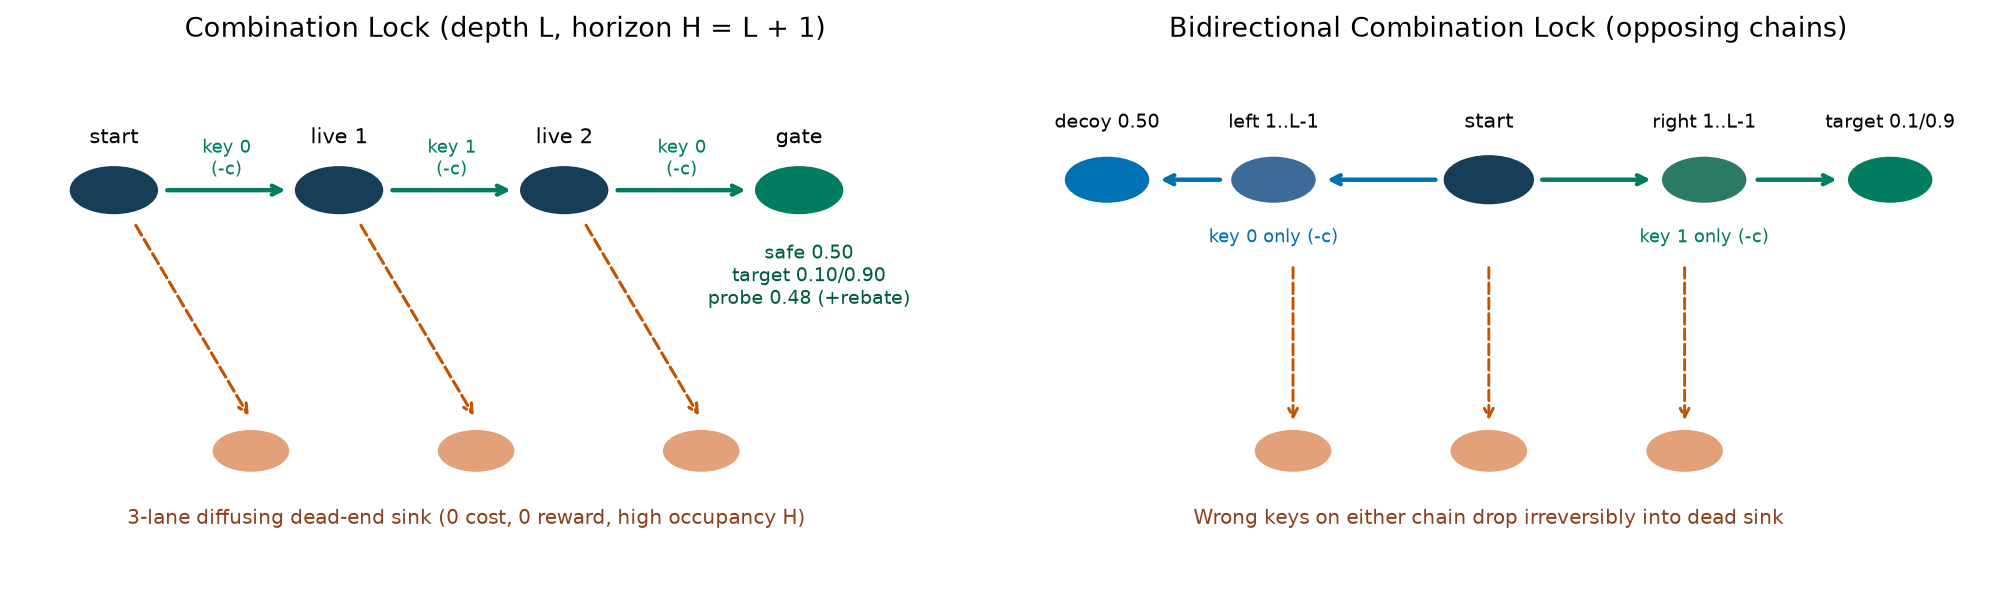

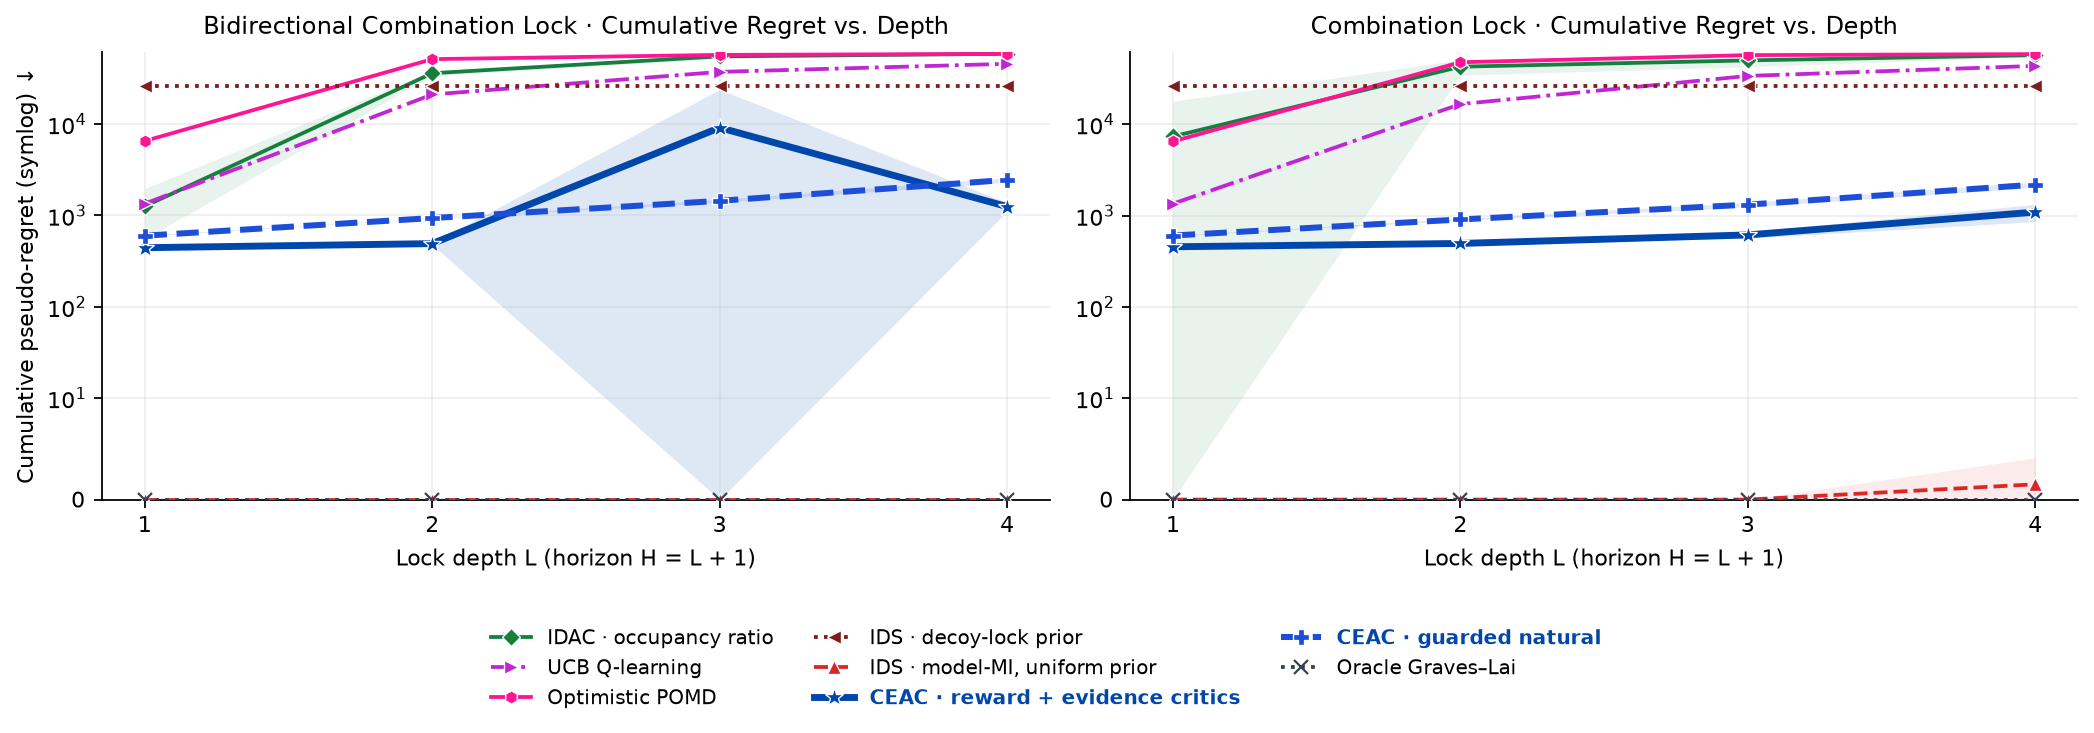

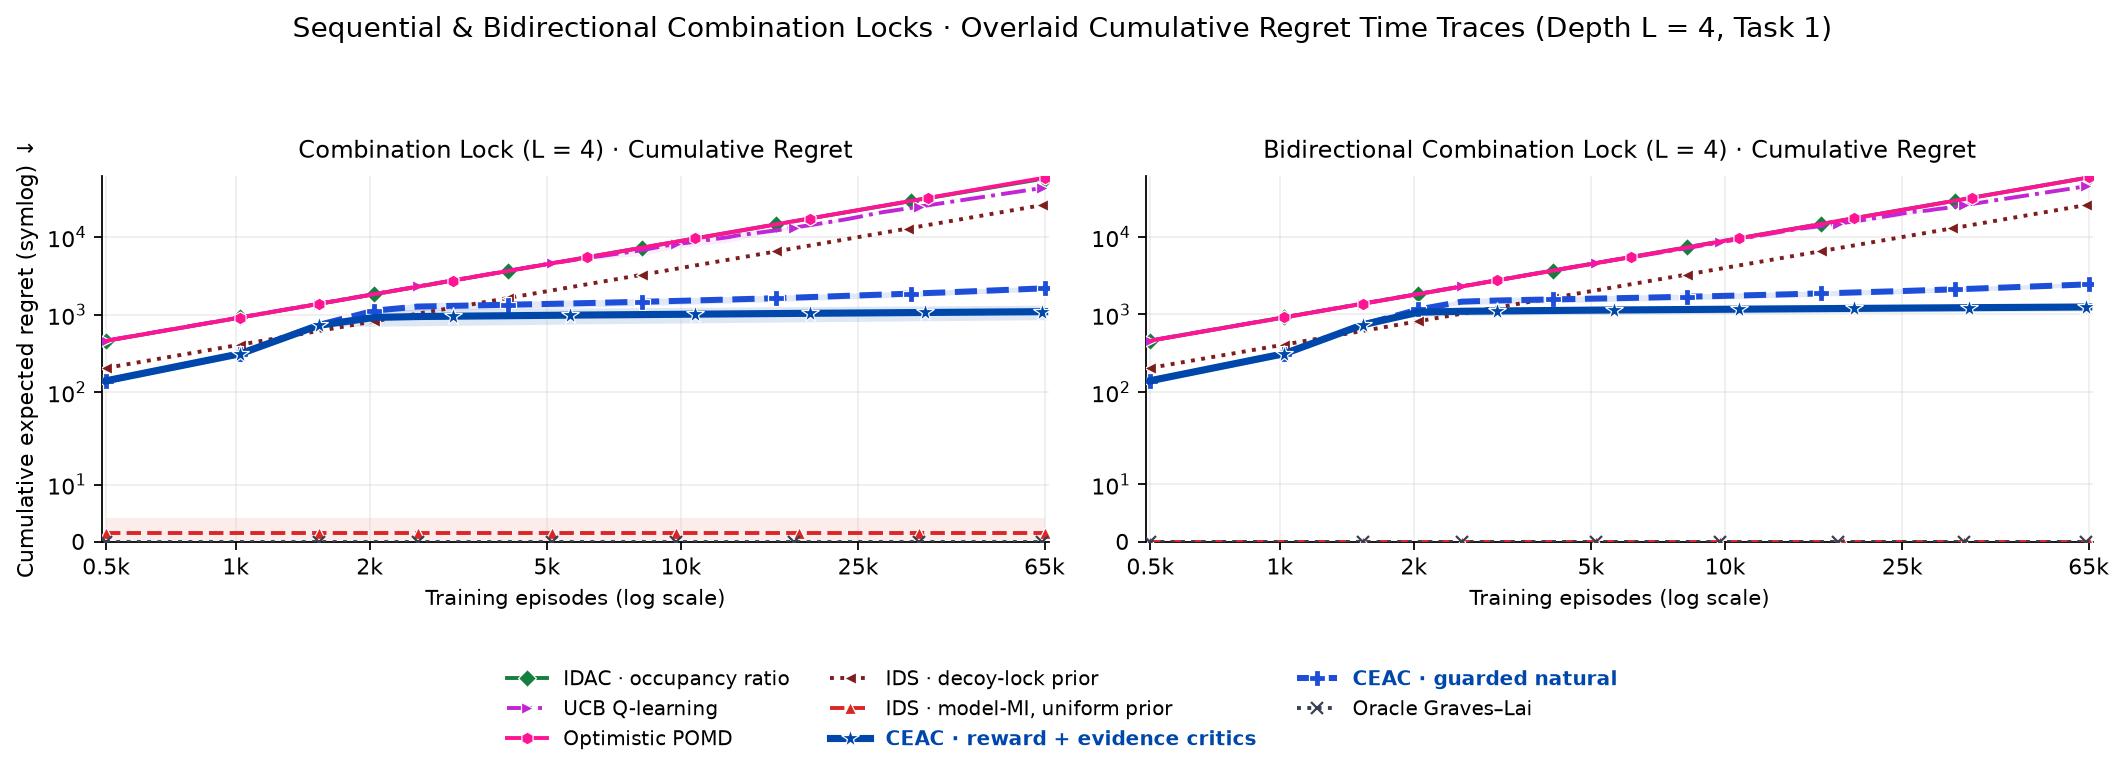

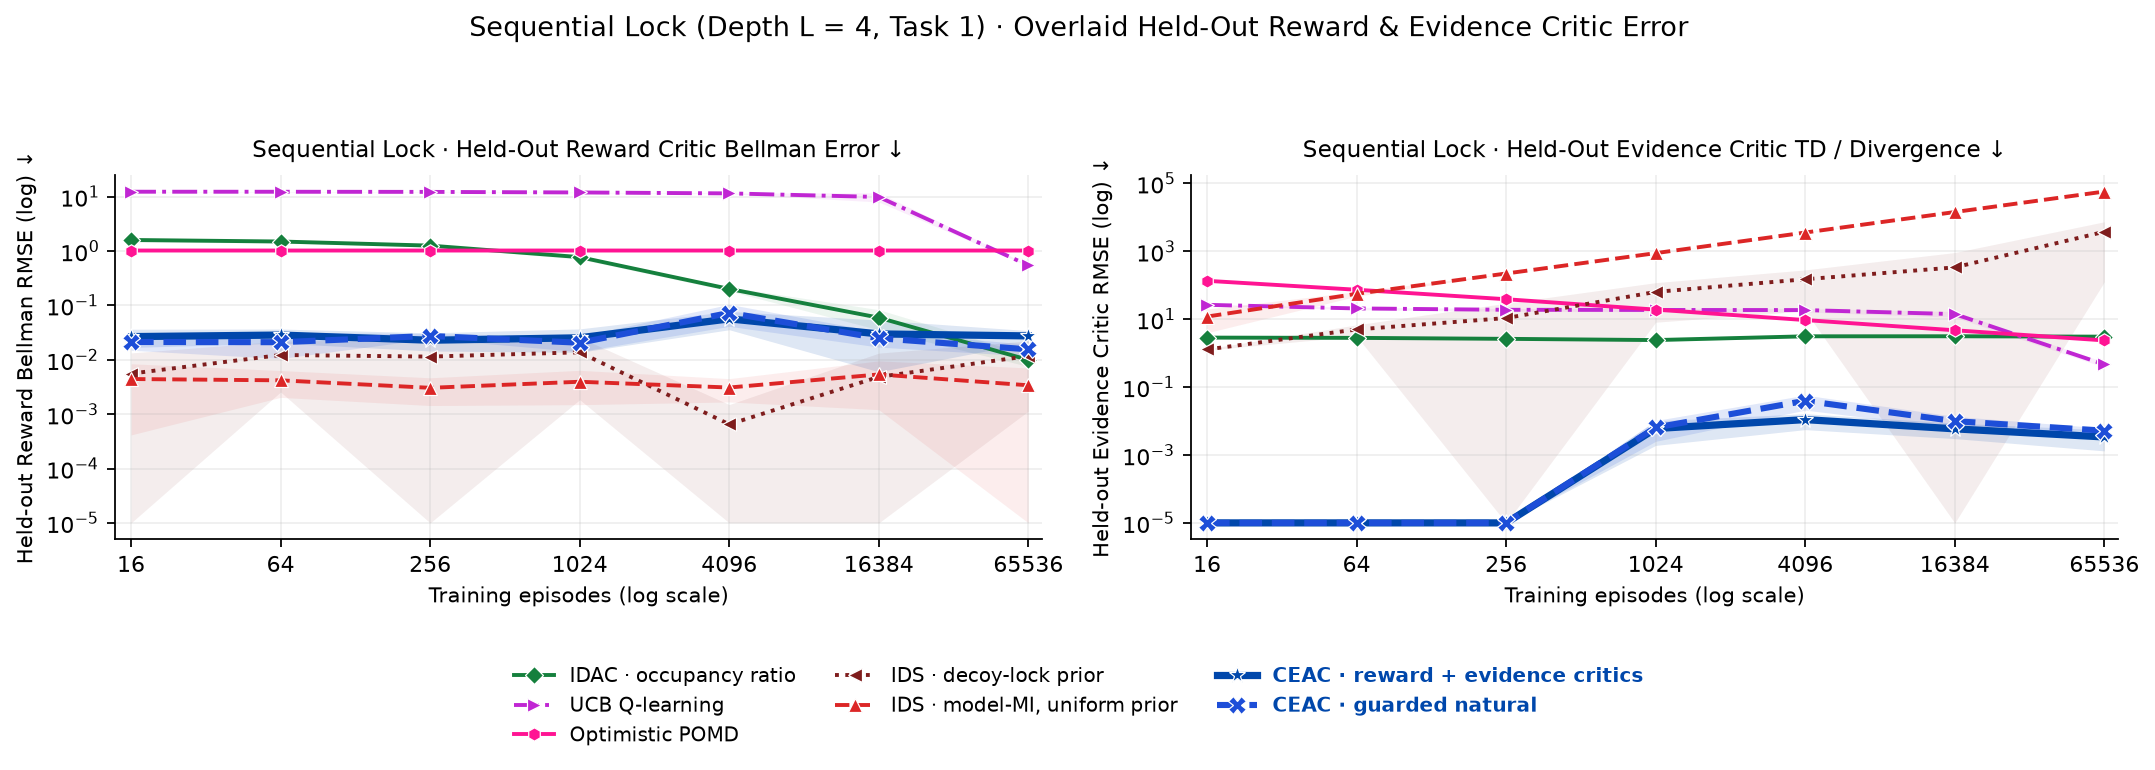

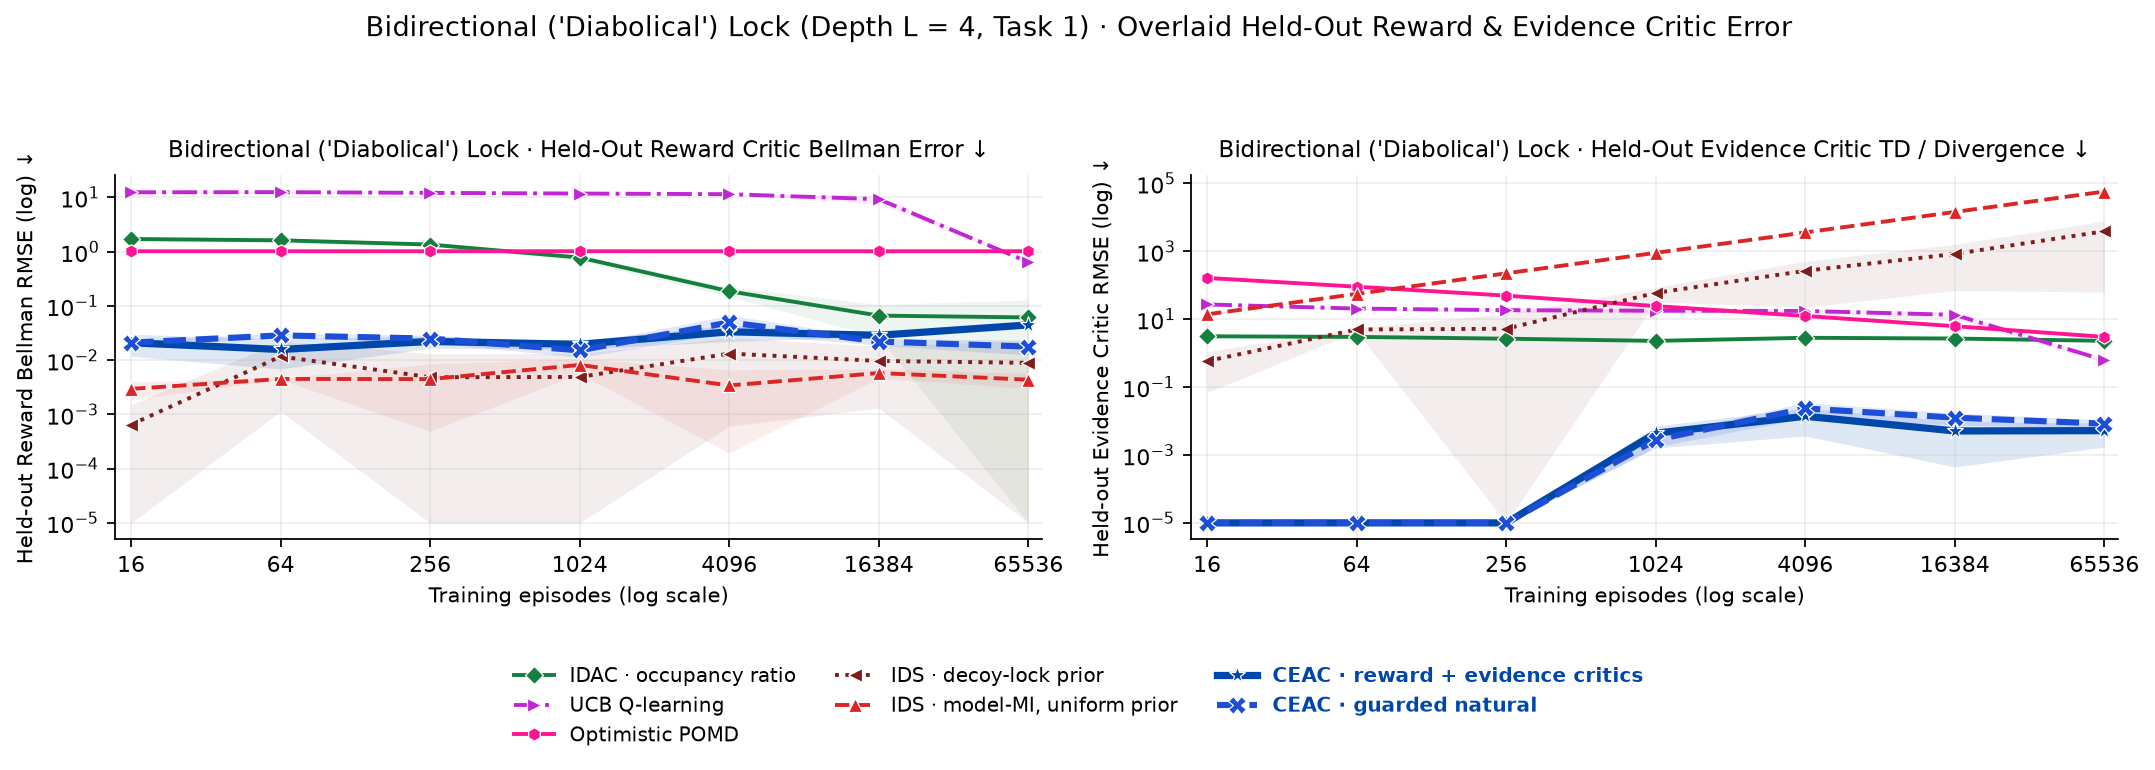

In [2]:
fig = draw_architecture("locks")
plt.show()
fig = draw_response(locks)
plt.show()
fig = draw_locks_overlaid_performance(locks, dose=4, task=1, metric="cumulative_regret")
plt.show()
spec_locks = SUITE_SPECS["locks"]
for k_key, k_title in spec_locks["kinds"]:
    fig = draw_suite_critic_traces(
        locks_critic["cells"],
        [(k_key, k_title)],
        target_dose=spec_locks["target_dose"],
        suptitle=f"{k_title} (Depth L = 4, Task 1) · Overlaid Held-Out Reward & Evidence Critic Error",
        method_order=spec_locks["methods"],
    )
    plt.show()


---
## Part II — Signalling Pathway Family (`epistatic_signalling` $\to$ `signalling_rewiring`)

### 2.1 Single-Stage Epistatic Signalling under Off-Pathway Pleiotropy (`epistatic_signalling`)

Tests discovery of a $1$-in-$128$ synthetic-rescue subtype (`K1 ∧ K2` pays $0.90$ vs. $0.10$) amidst $k \in \{0, 1, 2, 3\}$ non-causal passenger-omics channels ($M = 128 \cdot 2^k$) and $4^k - 1$ off-pathway pleiotropic states. Because the optimal action is **not** multi-step path-dependent here, whole-model MI `ids_product` wastes episodes profiling passengers while single-step Russo–Van Roy Optimal-Action IDS (`ids_action`, ruby red) and `ceac` (cobalt) ignore passenger channels.


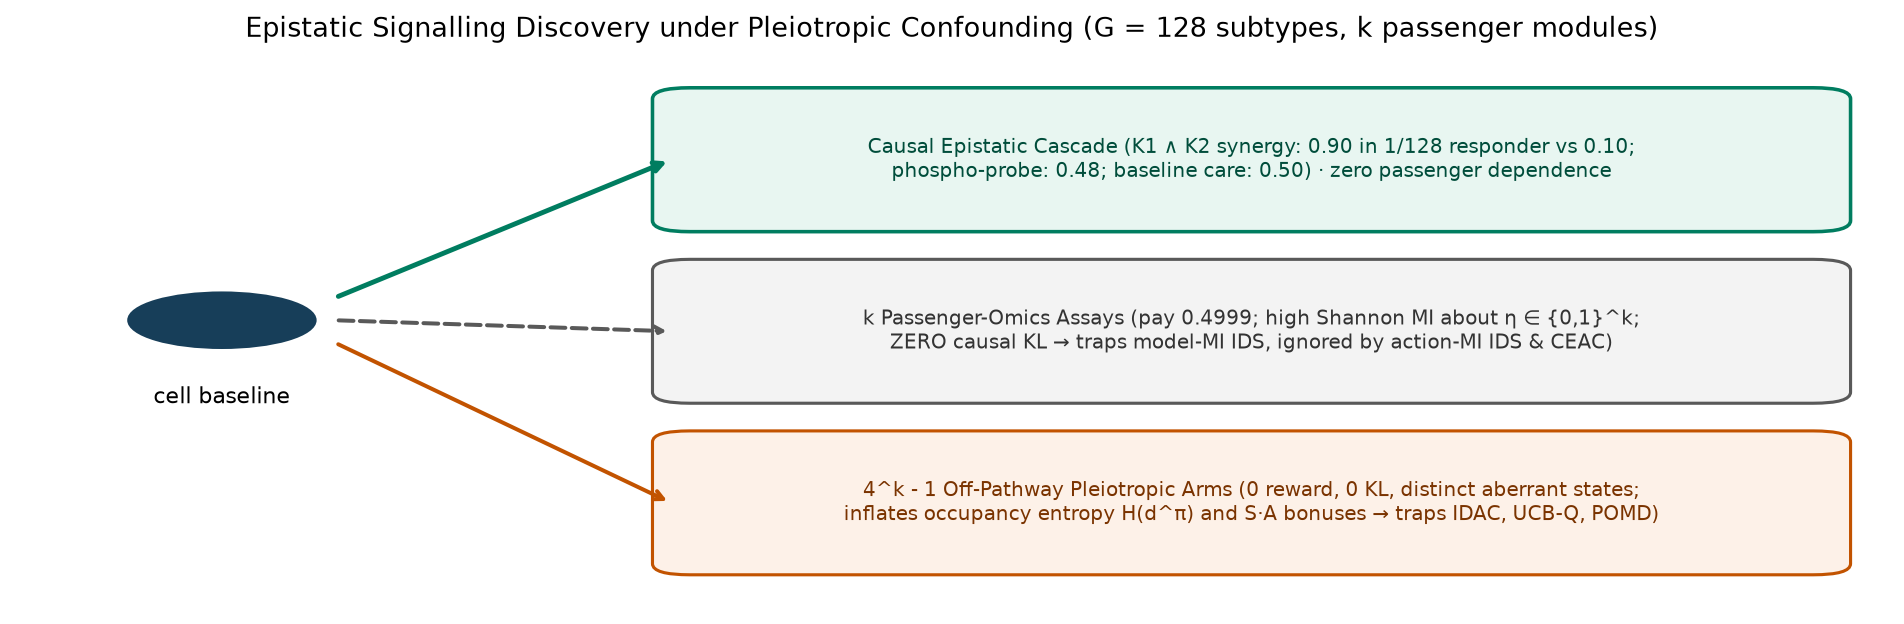

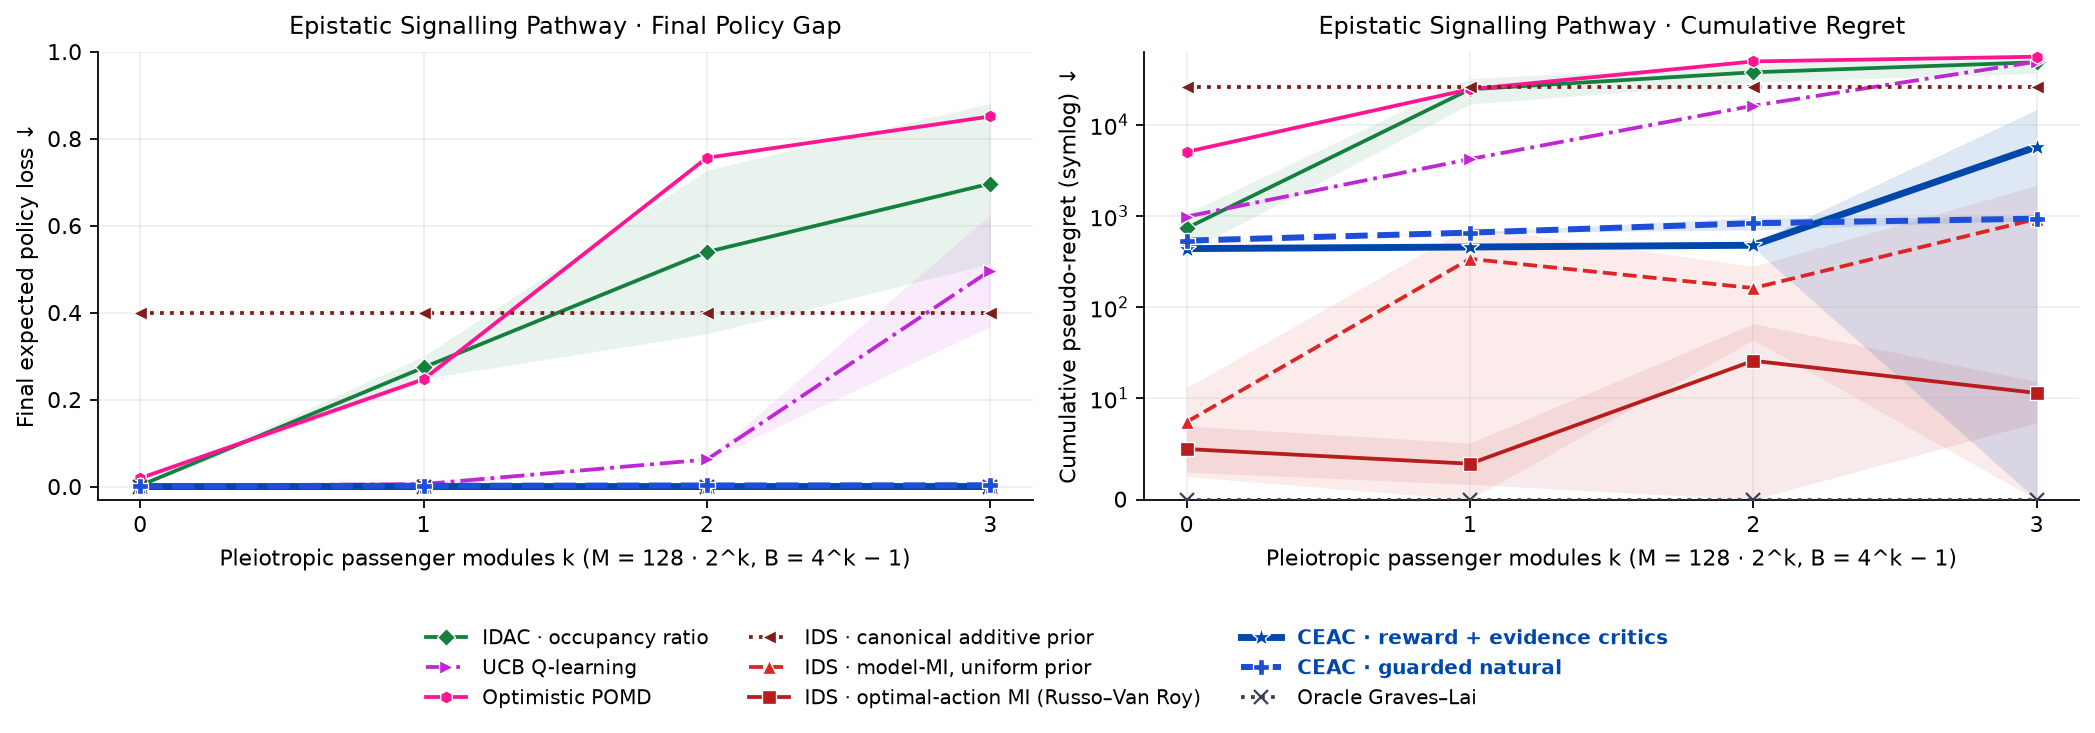

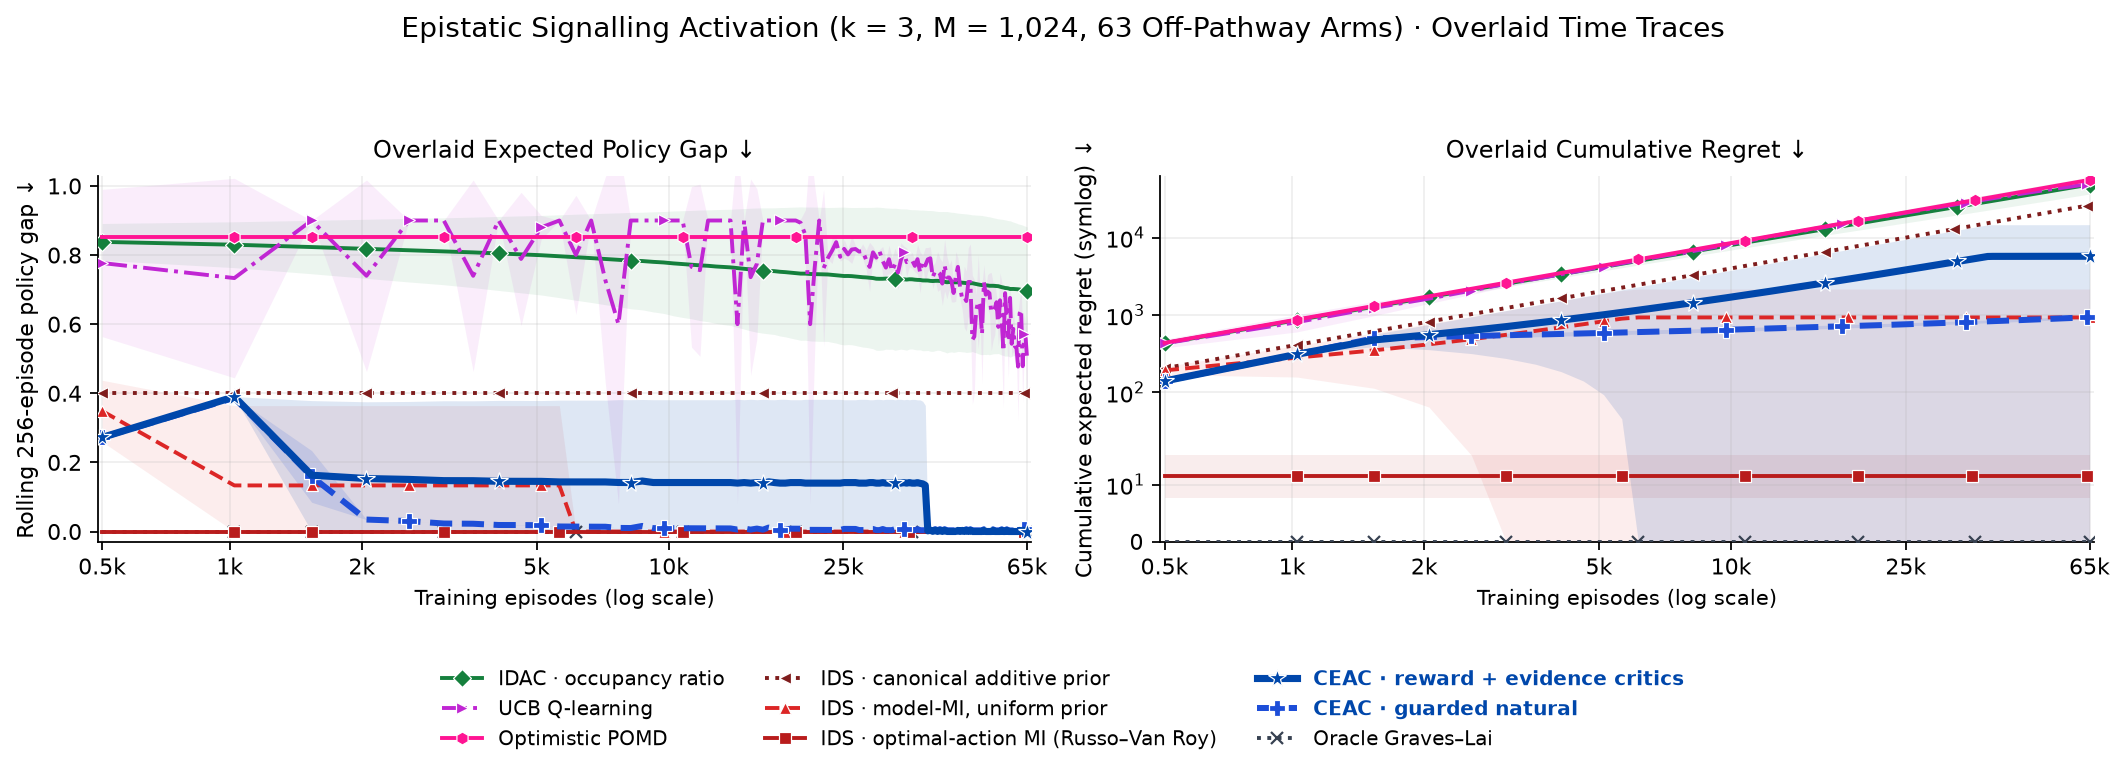

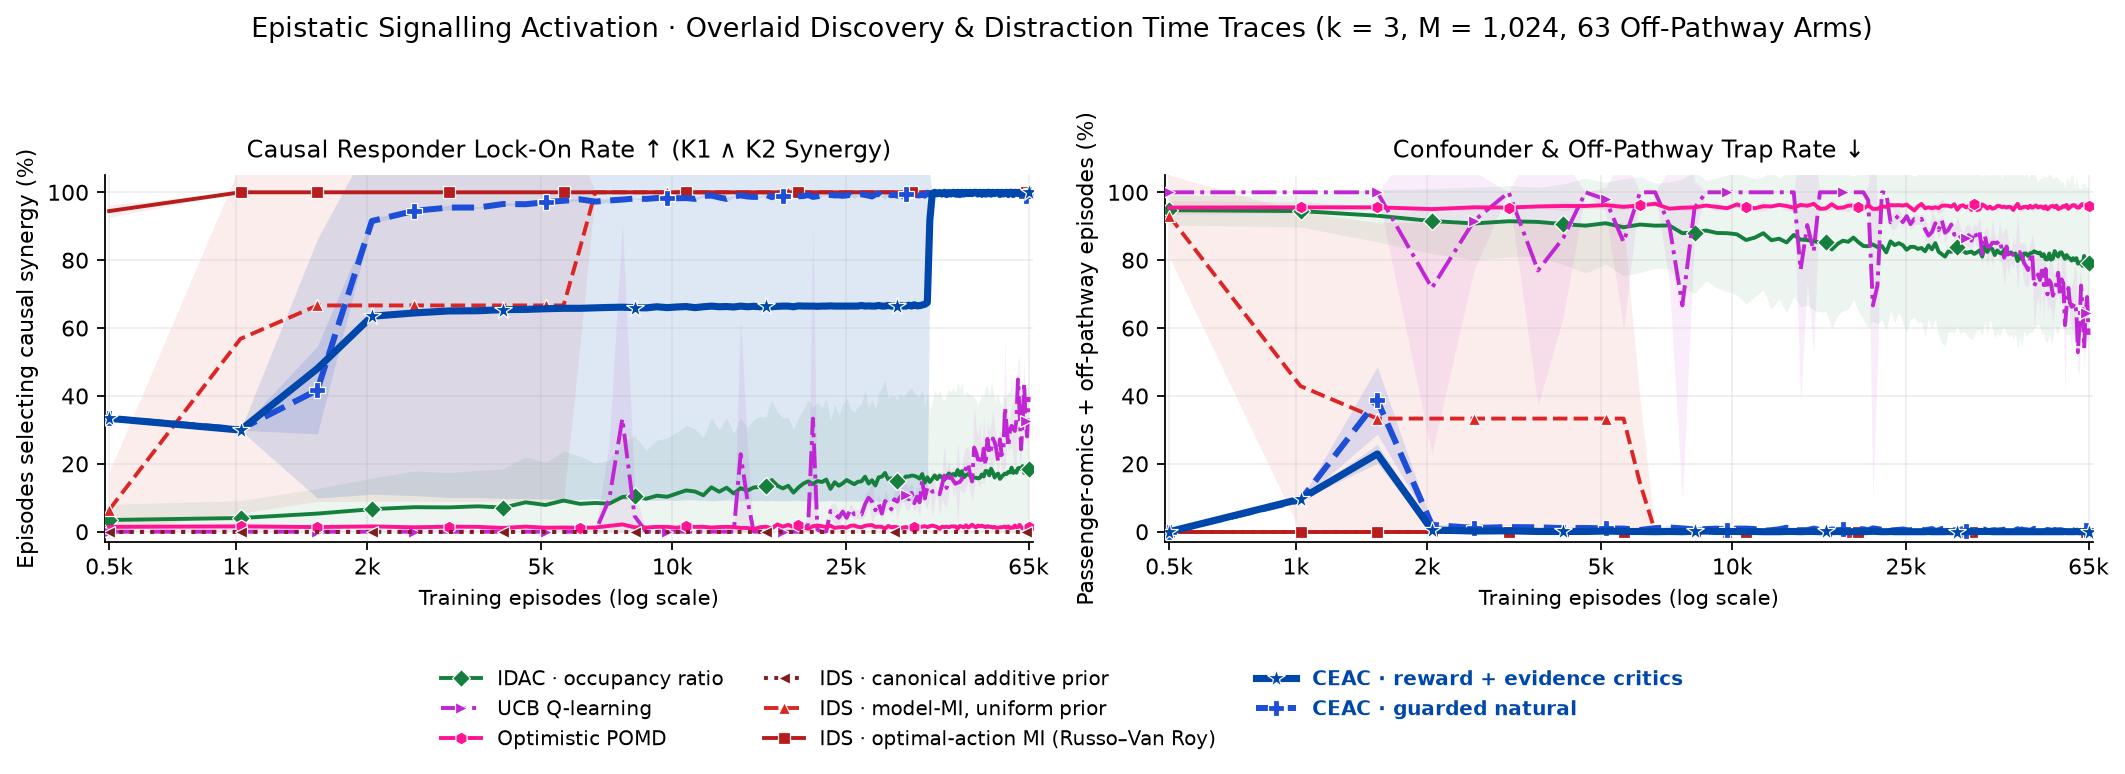

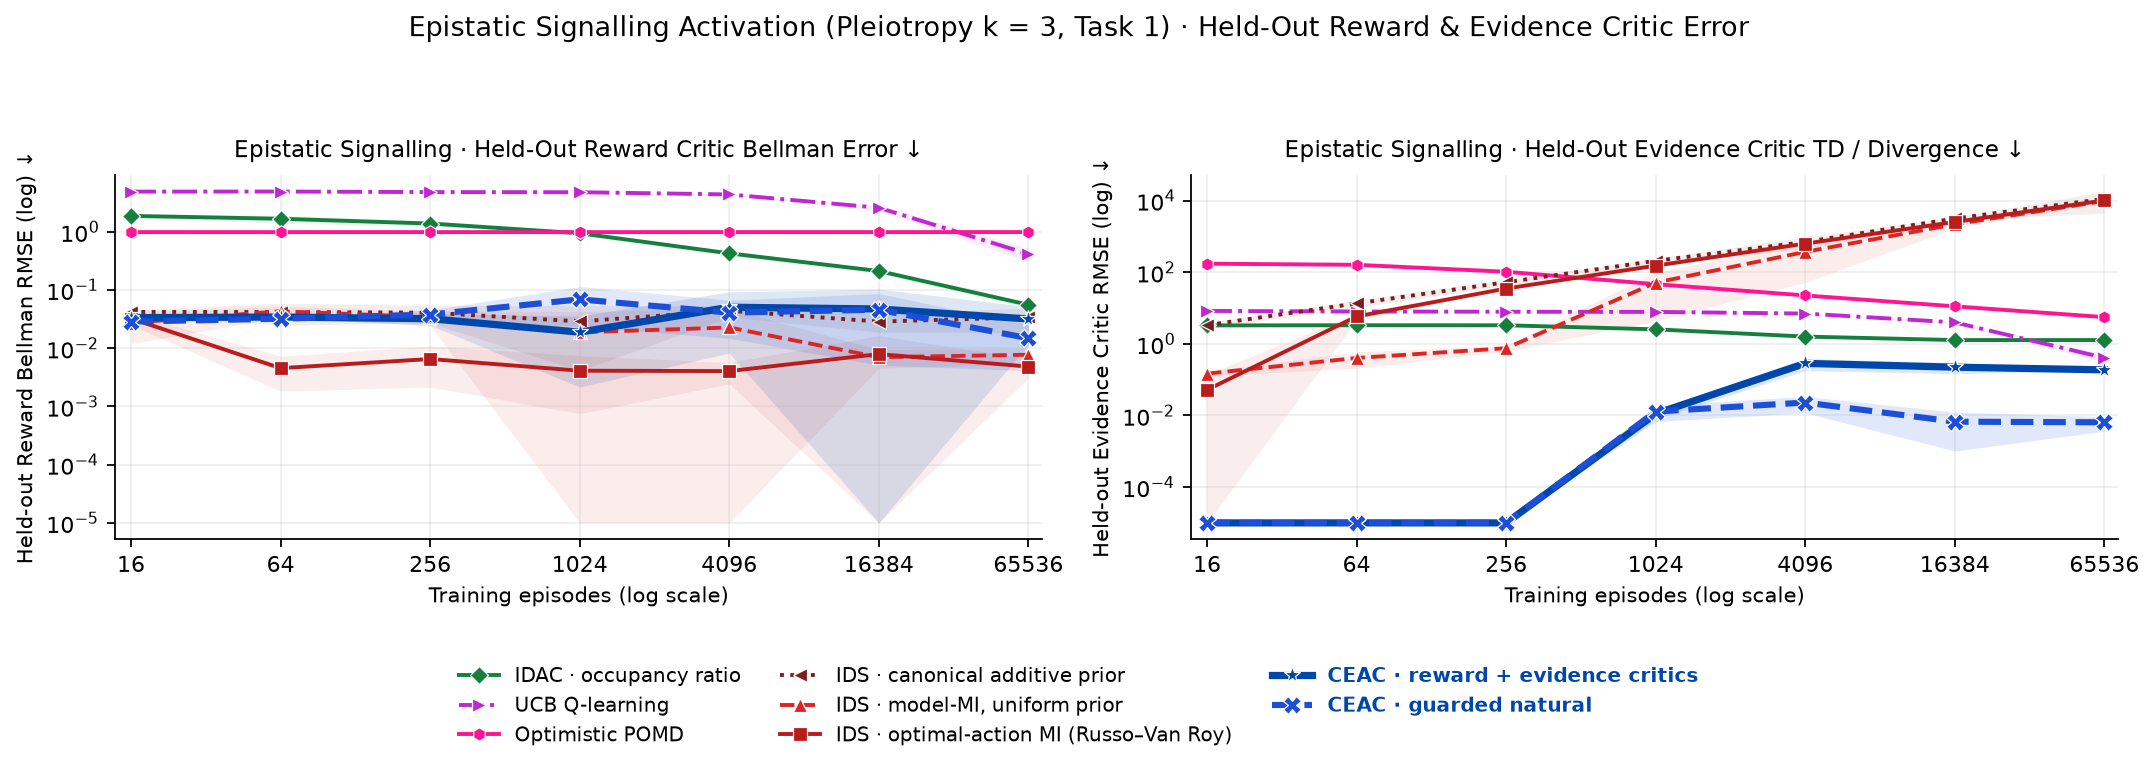

In [3]:
fig = draw_architecture("epistasis")
plt.show()
fig = draw_response(epistasis)
plt.show()
fig = draw_epistasis_overlaid_performance(epistasis, task=1, dose=3)
plt.show()
fig = draw_epistasis_discovery_traces(epistasis, dose=3, task=1)
plt.show()
spec_epi = SUITE_SPECS["epistasis"]
fig = draw_suite_critic_traces(
    epistasis_critic["cells"],
    spec_epi["kinds"],
    target_dose=spec_epi["target_dose"],
    suptitle=spec_epi["traces_title"],
    method_order=spec_epi["methods"],
)
plt.show()


### 2.2 Multi-Step Path-Dependent Signalling Rewiring (`signalling_rewiring`, $H = 3$) — Breaking Optimal-Action IDS

When the optimal intervention becomes **state-contingent across steps** — requiring Step-1 `EGFR/MEK` priming ($-0.015$, $0$ immediate KL) to relieve negative feedback and unlock $R = 8$ post-translational bypass co-targets ($0.92$ vs. $0.10$), while unprimed Step-1 co-targeting fails ($0.25$) — **both** multi-step Optimal-Action IDS formulations break as confounding complexity $k \in \{0, 1, 2, 3\}$ increases:
- **`ids_action_tree` ($I(\Pi^\star; Z)$, coral red)**: $(3^k - 1)$ off-path stress states carry $\xi$-dependent local rescues, splitting Bellman optimal policy trees $\Pi^\star(\theta, \xi)$ by $2^k$.
- **`ids_action_onpath` ($I(C_{\text{on-path}}^\star; Z)$, ruby red)**: $6k$ coarse mRNA echo clades ($0.49999$) carry positive scalar MI about marginal peripheral clades ($0.5004$) while yielding **zero KL** on the post-translational bypass responder.
- **Periwinkle `ceac_ranked`**: Stays flat near `~40` regret and `0.0001` gap across all $k = 0 \to 3$, with Held-Out Evidence Critic RMSE converging smoothly to `0.0000`.


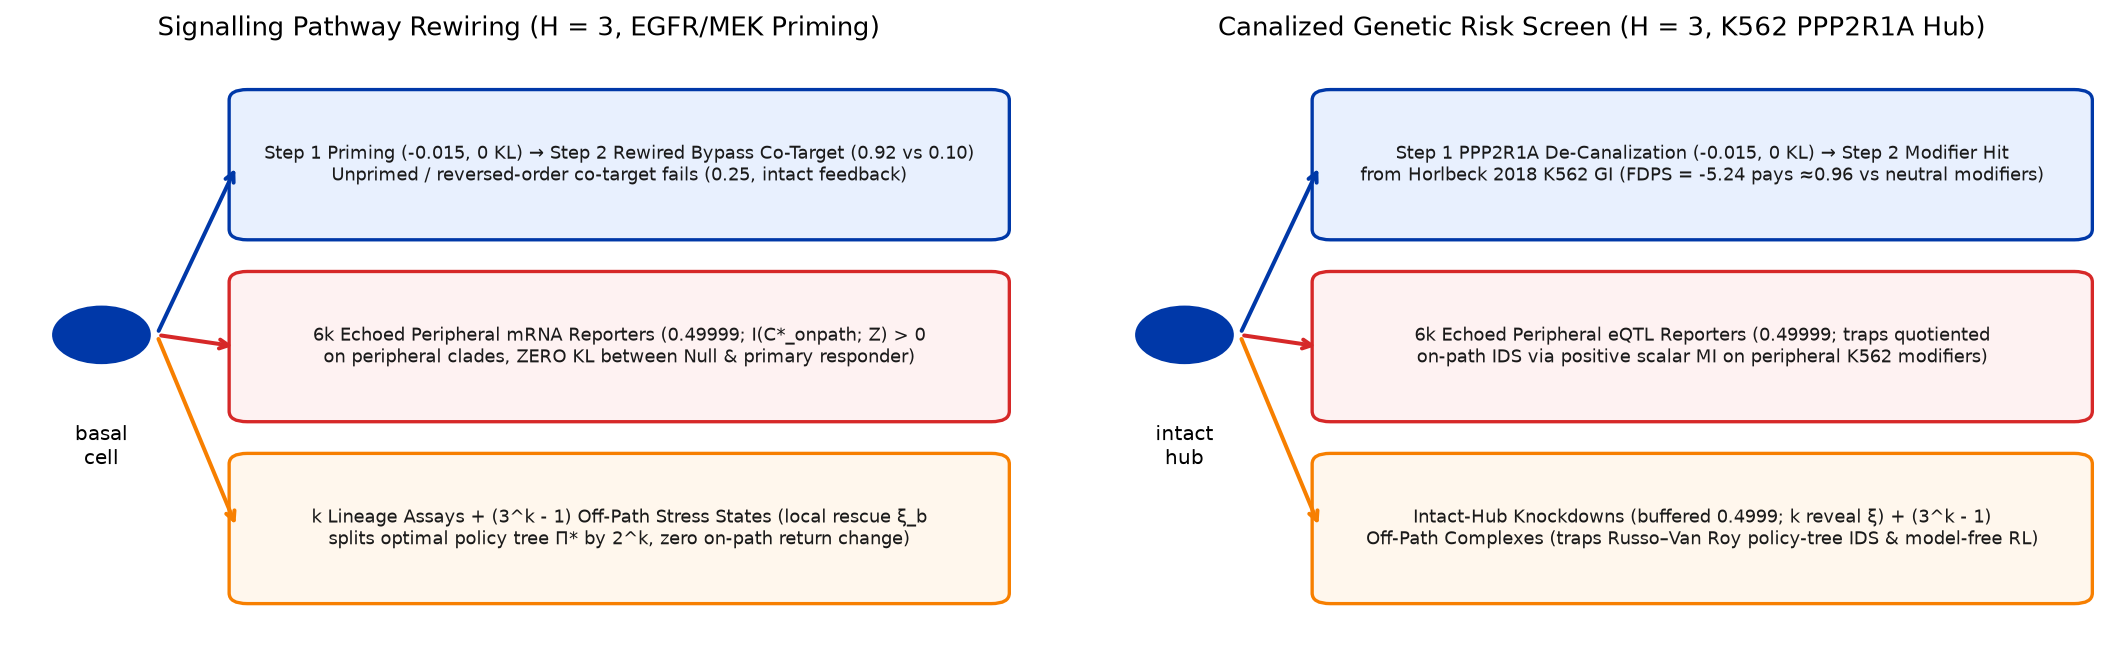

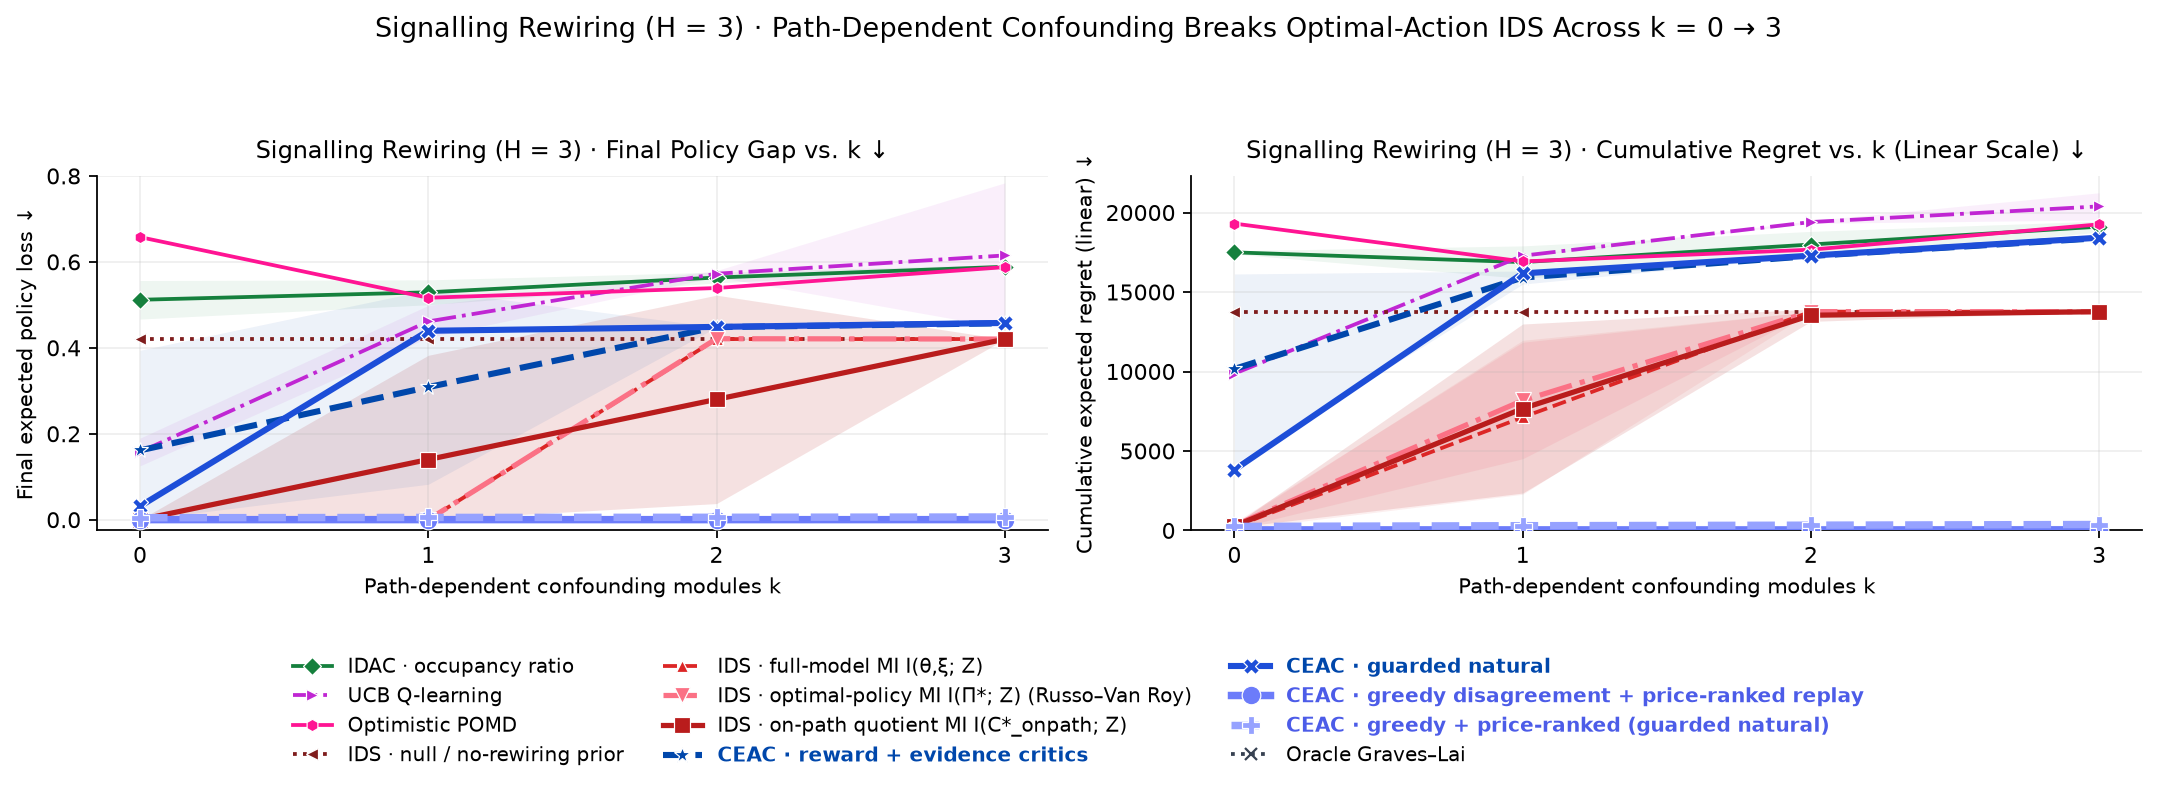

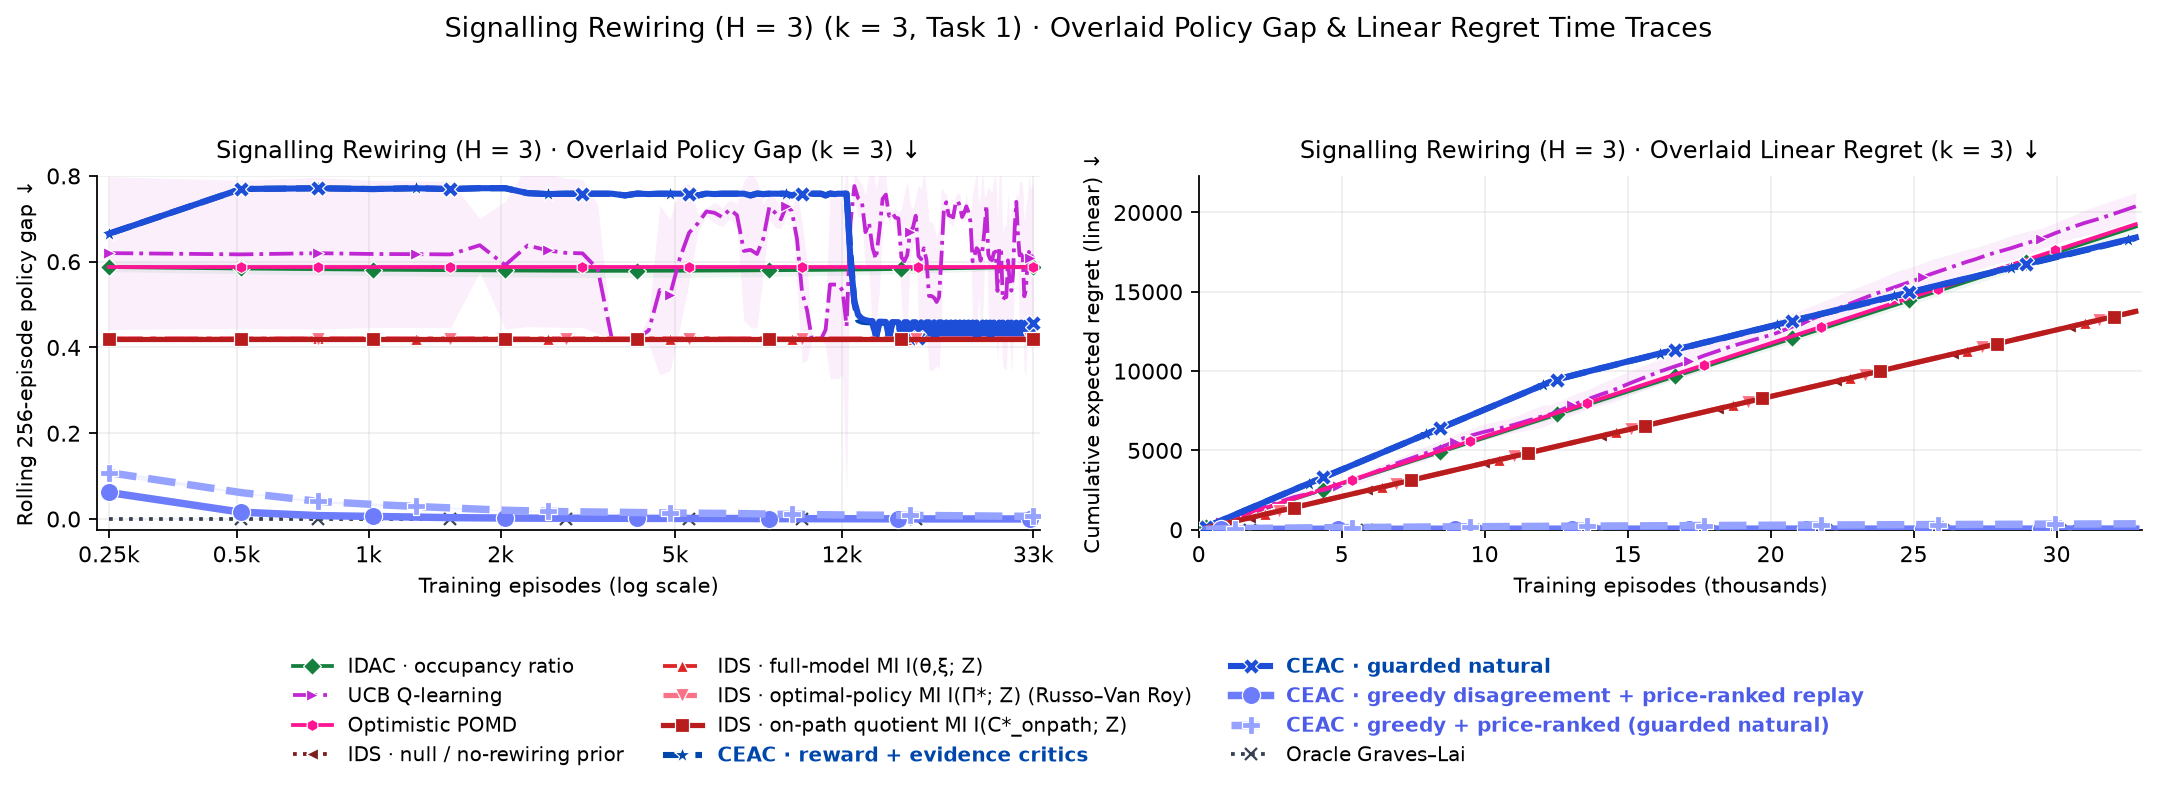

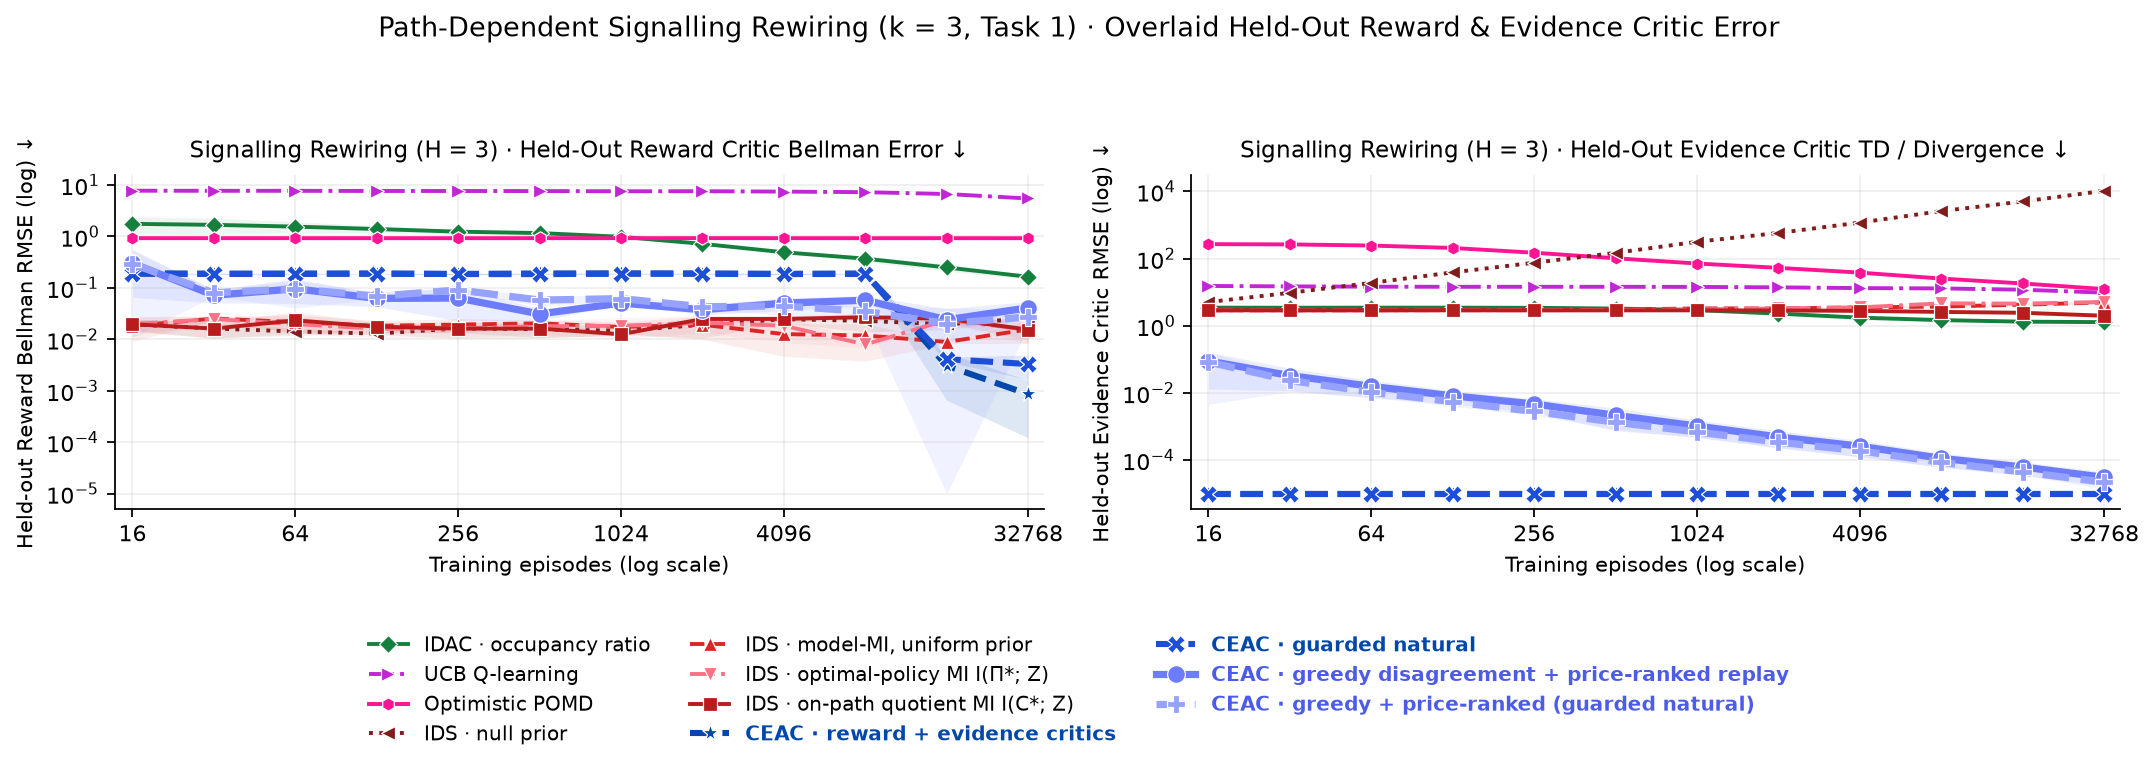

In [4]:
fig = draw_pathdep_architecture()
plt.show()
fig = draw_single_pathdep_scaling(pathdep["summary_rows"], "signalling_rewiring")
plt.show()
fig = draw_single_pathdep_traces(pathdep, "signalling_rewiring", dose=3)
plt.show()
fig = draw_suite_critic_traces(
    critic_audit["cells"],
    [("signalling_rewiring", "Signalling Rewiring (H = 3)")],
    target_dose=3,
    suptitle="Path-Dependent Signalling Rewiring (k = 3, Task 1) · Overlaid Held-Out Reward & Evidence Critic Error",
    method_order=list(PATHDEP_AUDIT_METHODS),
    ranked_ceac_present=True,
)
plt.show()


---
## Part III — Human K562 Genetic Interaction Family (Horlbeck et al., 2018)

### 3.1 Pairwise K562 Interaction Screens (`gi_arrayed` & `gi_multiplexed`) & Greedy Price-Ranked CEAC

Evaluates sequential pair discovery on a verified 10-variable / 45-pair K562 GI panel (`FDPS–PPP2R1A`, $\text{GI} = -5.2413$) under $k \in \{0, 1, 2, 3\}$ non-causal single-variable main-effect confounders ($M = 46 \cdot 2^k$). Periwinkle `ceac_ranked` eliminates the uniform 46-column seed-bank floor (`~2` active bank columns vs. `46`). Because the pairwise screen is single-stage, `ids_action` also remains low-regret here.


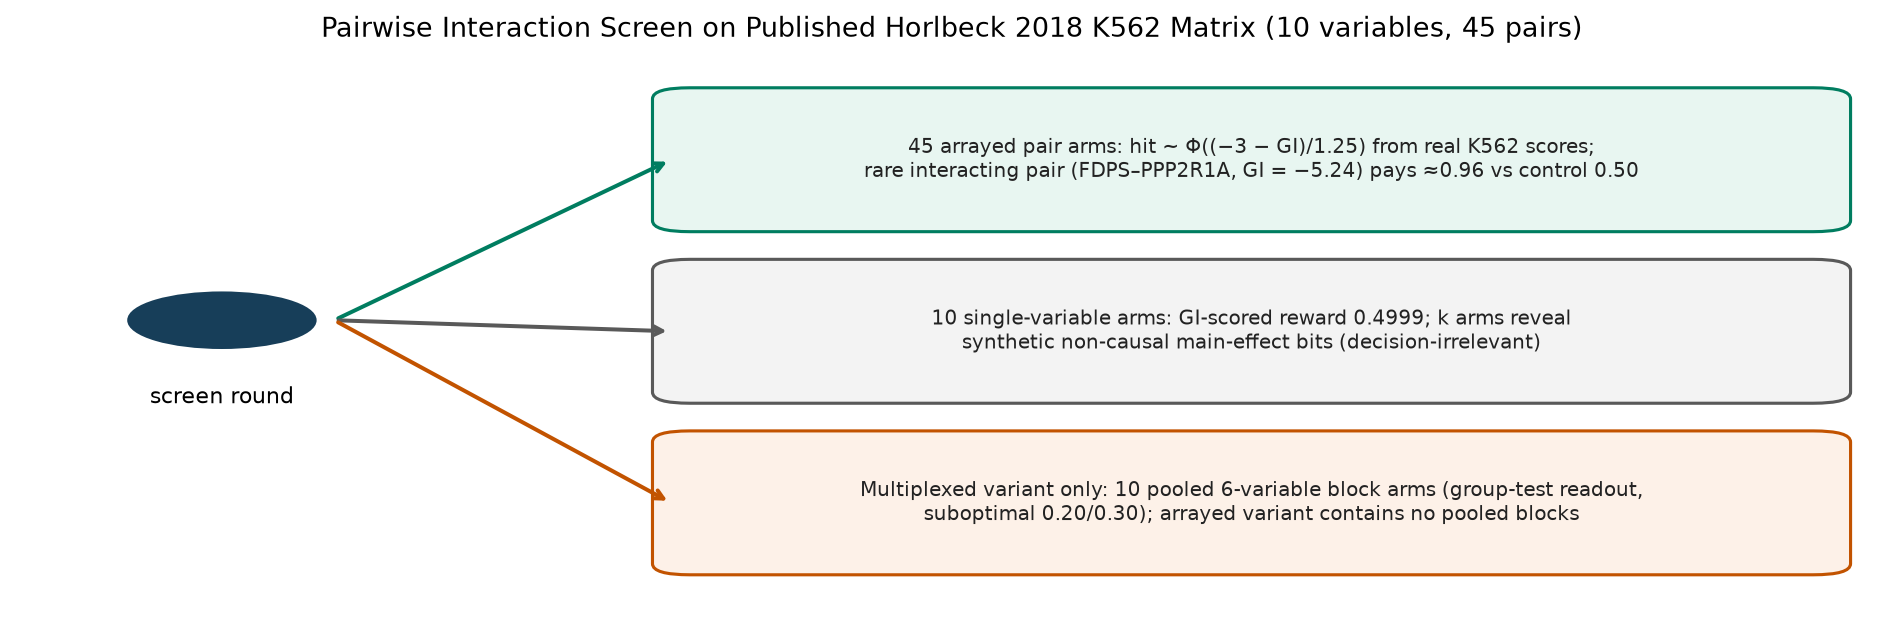

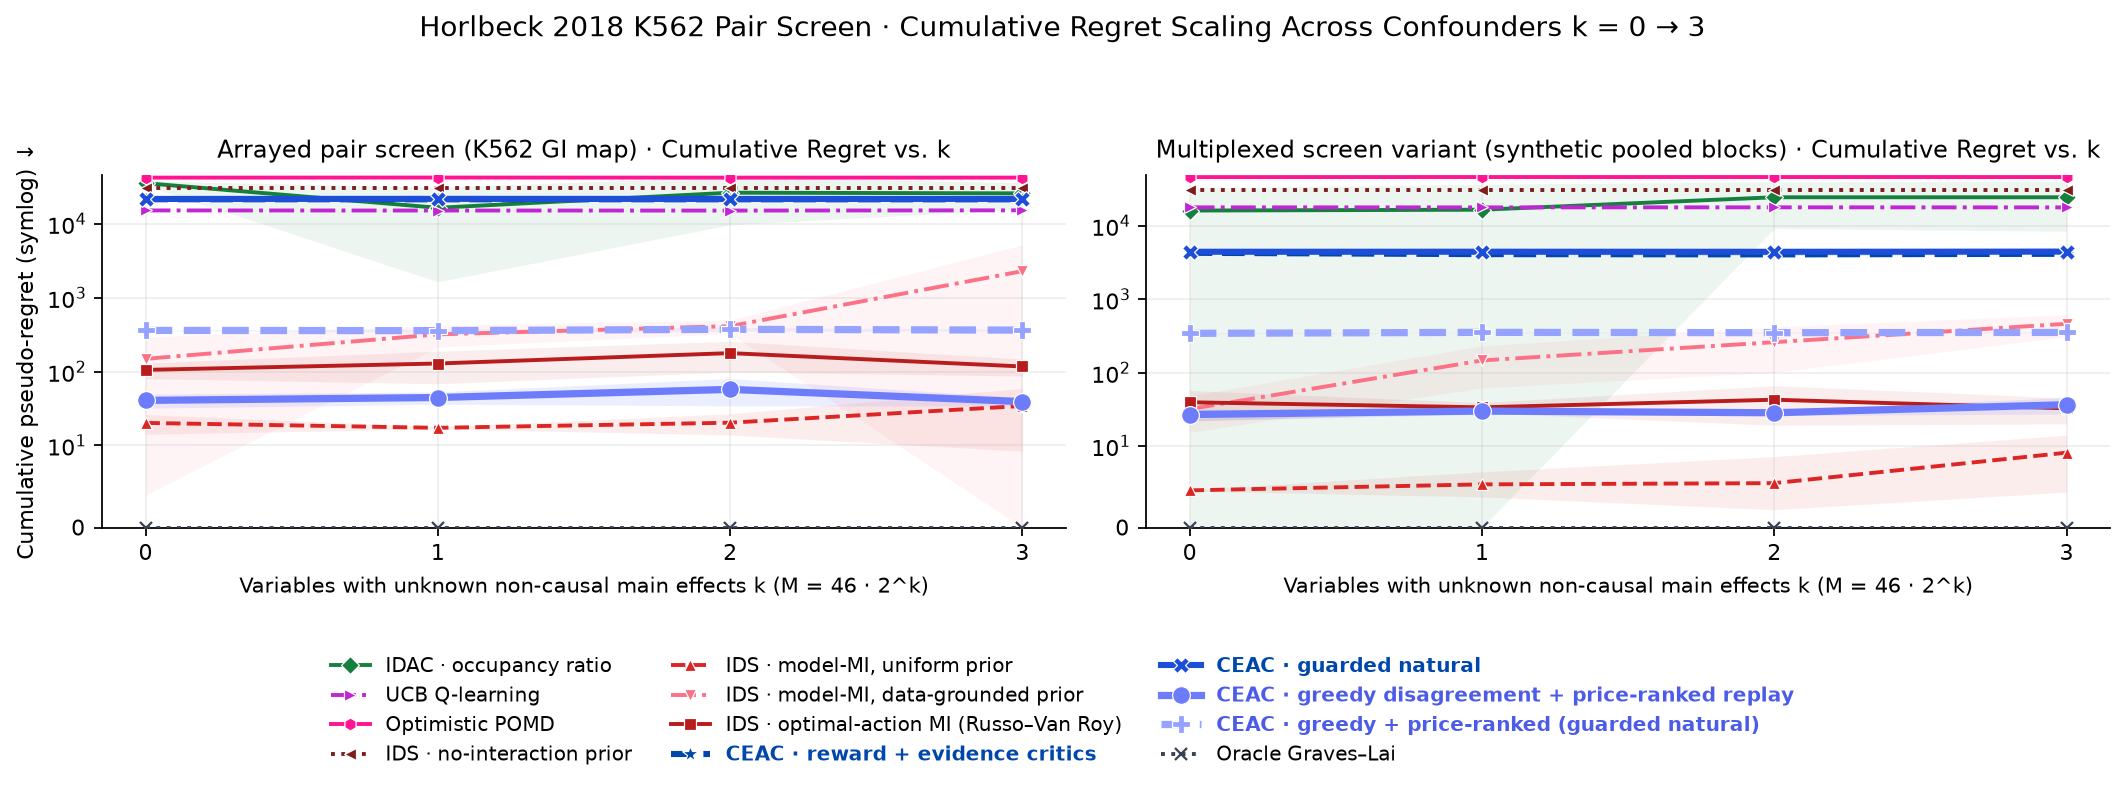

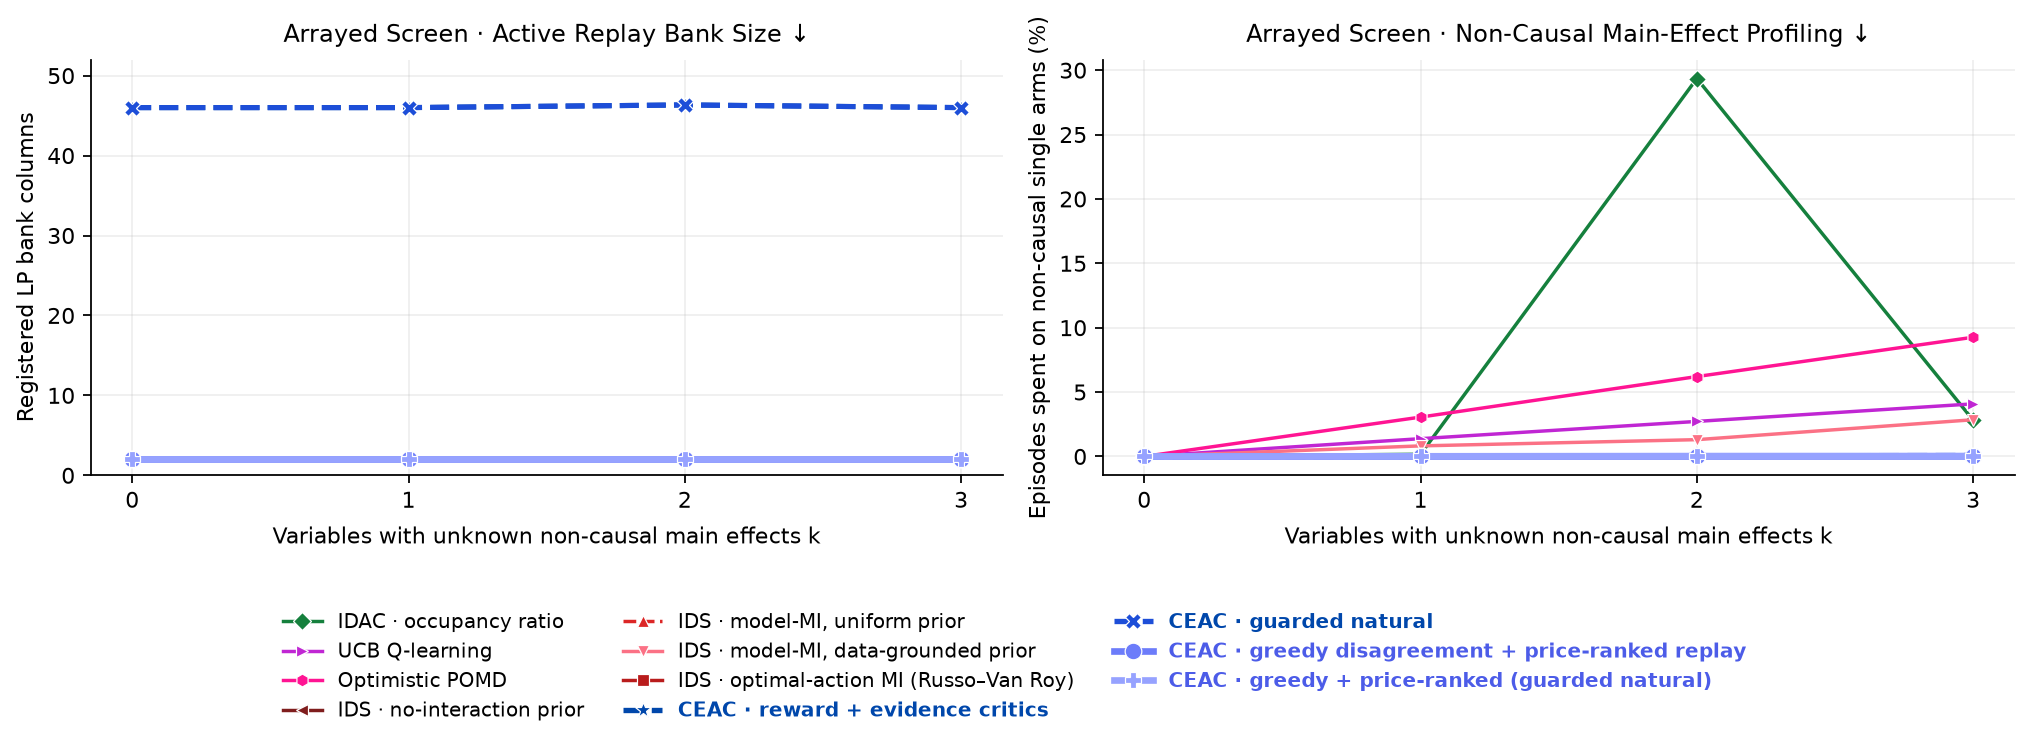

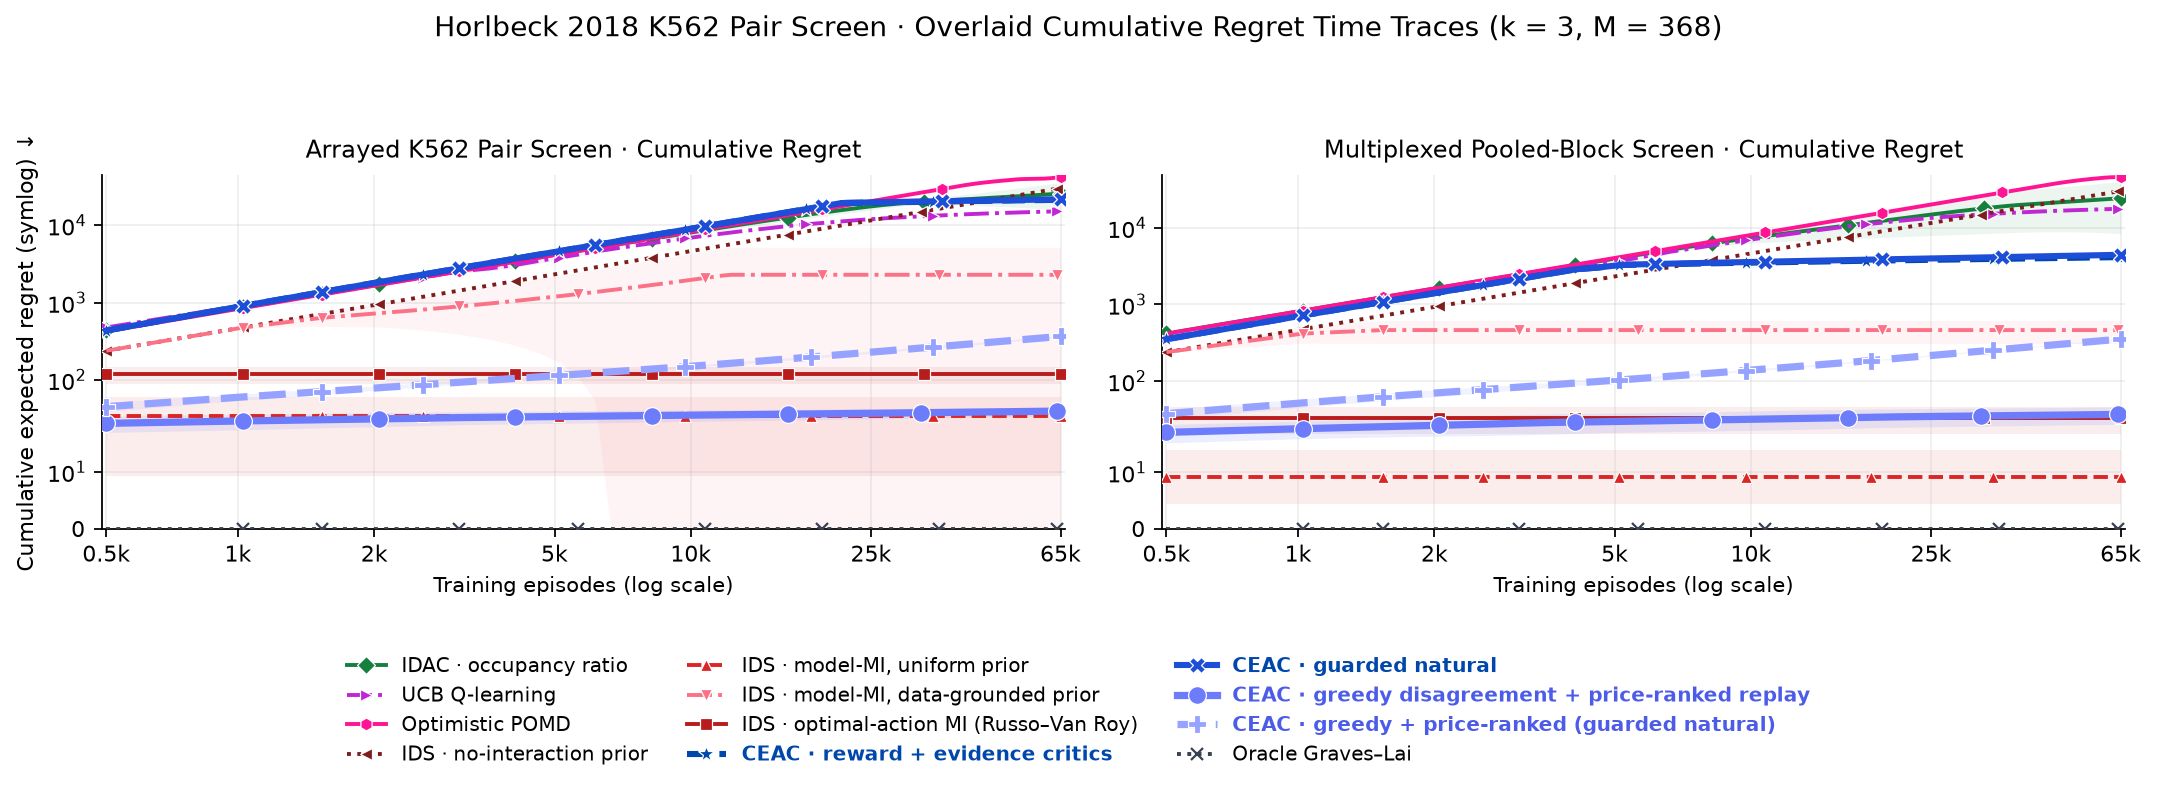

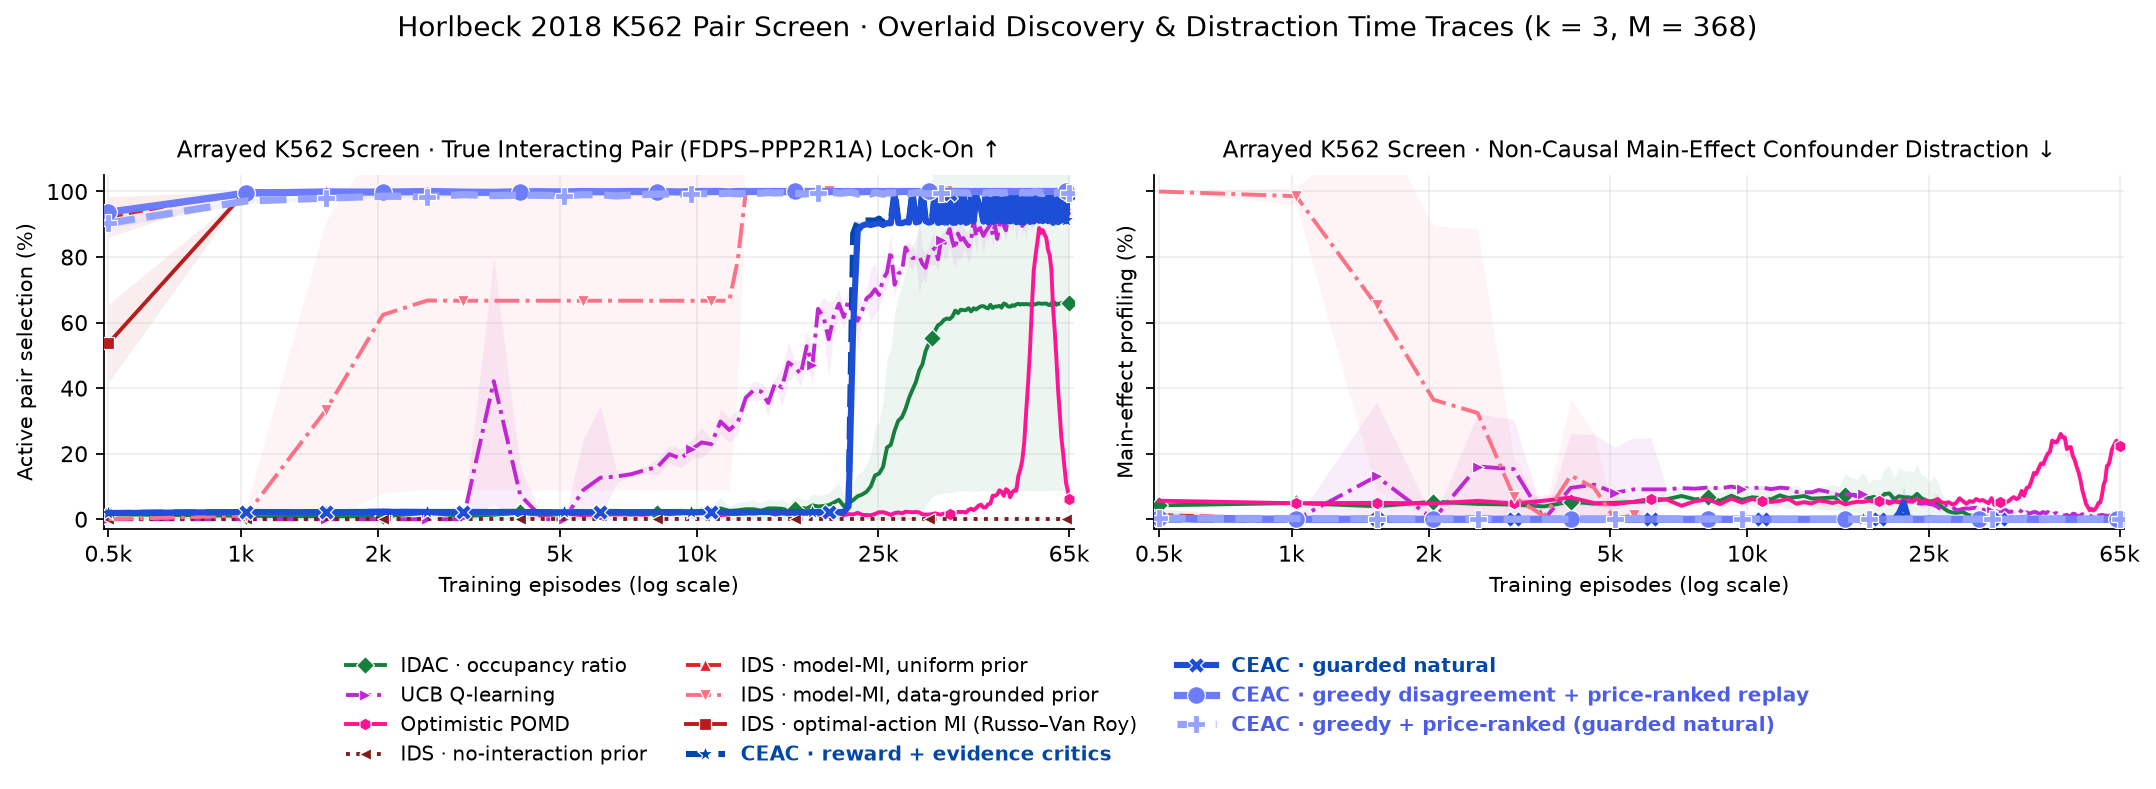

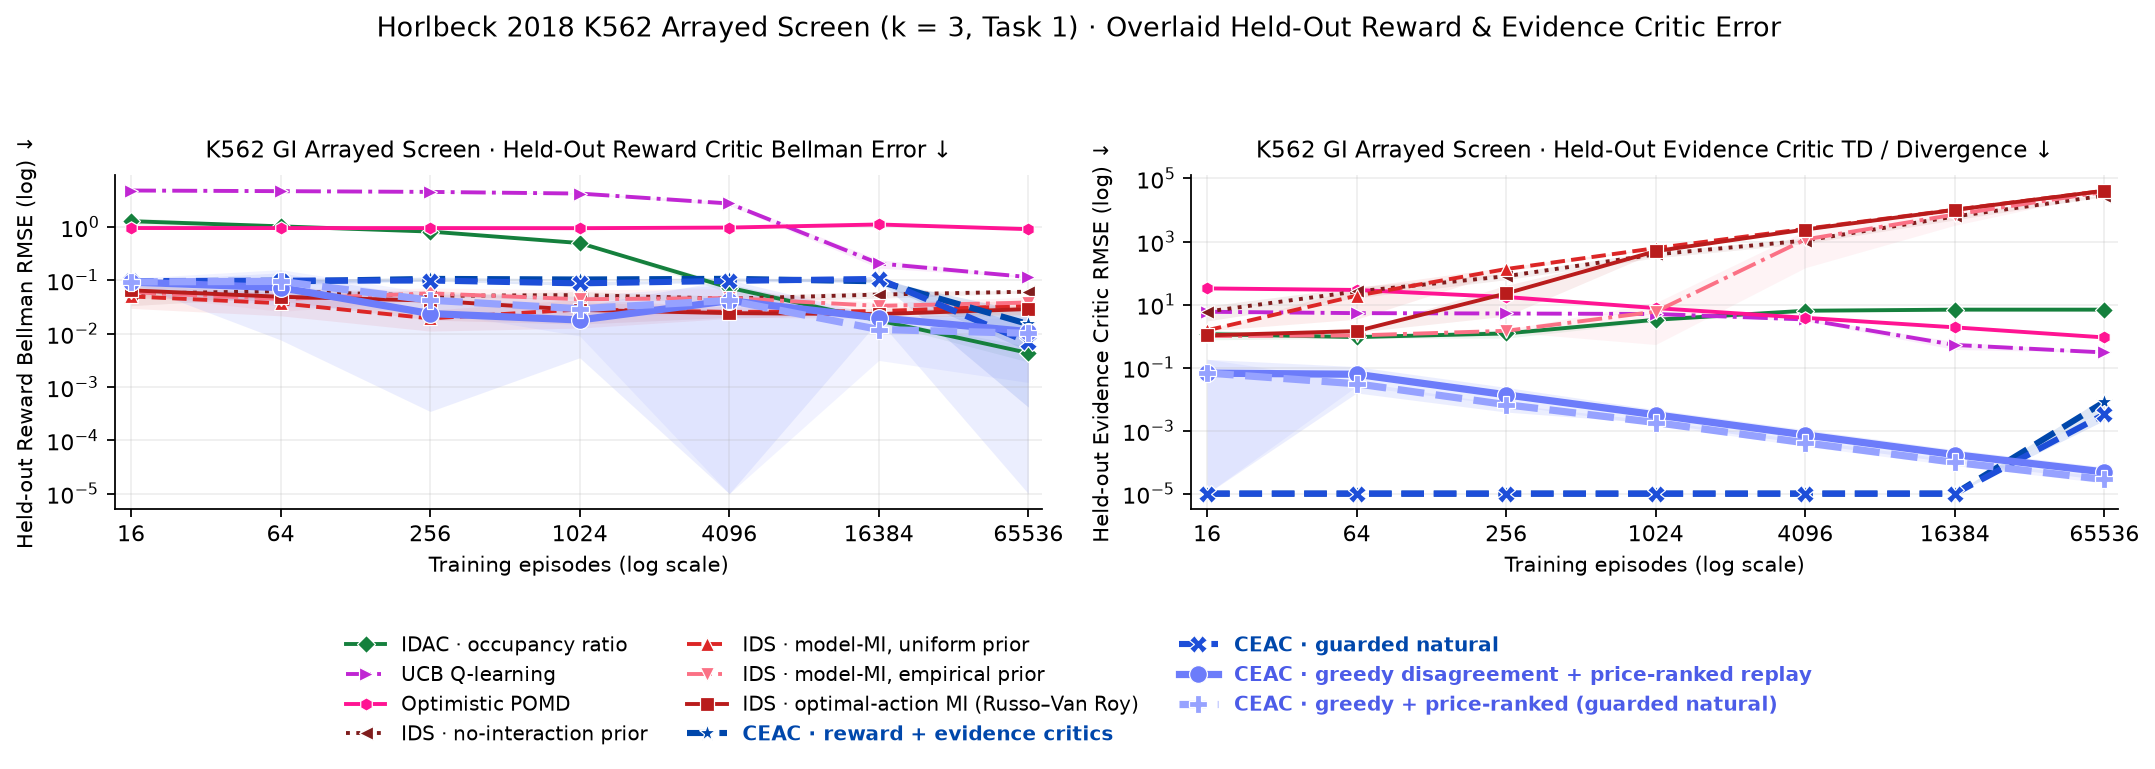

In [5]:
fig = draw_architecture("gi_screen")
plt.show()
fig = draw_gi_ranked_response(gi_ranked["summary_rows"])
plt.show()
fig = draw_gi_ranked_mechanisms(gi_ranked["summary_rows"])
plt.show()
fig = draw_gi_overlaid_performance(gi_ranked, dose=3, metric="cumulative_regret")
plt.show()
fig = draw_gi_discovery_traces(gi_ranked, dose=3)
plt.show()
spec_gi = SUITE_SPECS["gi_ranked"]
fig = draw_suite_critic_traces(
    gi_critic["cells"],
    [("gi_arrayed", "K562 GI Arrayed Screen")],
    target_dose=spec_gi["target_dose"],
    suptitle="Horlbeck 2018 K562 Arrayed Screen (k = 3, Task 1) · Overlaid Held-Out Reward & Evidence Critic Error",
    method_order=spec_gi["methods"],
    ranked_ceac_present=True,
)
plt.show()


### 3.2 Multi-Step Canalized K562 Genetic Risk Screen (`canalized_gi`, `PPP2R1A` Hub, $H = 3$) — Breaking Optimal-Action IDS

Models **phenotypic canalization** on the real K562 `PPP2R1A` phosphatase hub ($H = 3$, `32,768` episodes): single-gene knockdowns under an intact `PPP2R1A` hub are buffered ($0.4999$), whereas Step-1 `PPP2R1A` de-canalization ($-0.015$, $0$ immediate KL) exposes second-step K562 synthetic-lethal modifiers (`FDPS`, hit $\approx 0.96$). Adding $6k$ peripheral eQTL-echoed modifiers and $(3^k - 1)$ off-path complexes breaks `ids_product`, Russo–Van Roy `ids_action_tree` ($I(\Pi^\star; Z)$), **and** quotiented `ids_action_onpath` ($I(C_{\text{on-path}}^\star; Z)$) across $k = 0 \to 3$, while periwinkle `ceac_ranked` stays flat near `~38` regret with `0.0001` Held-Out Evidence Critic RMSE.


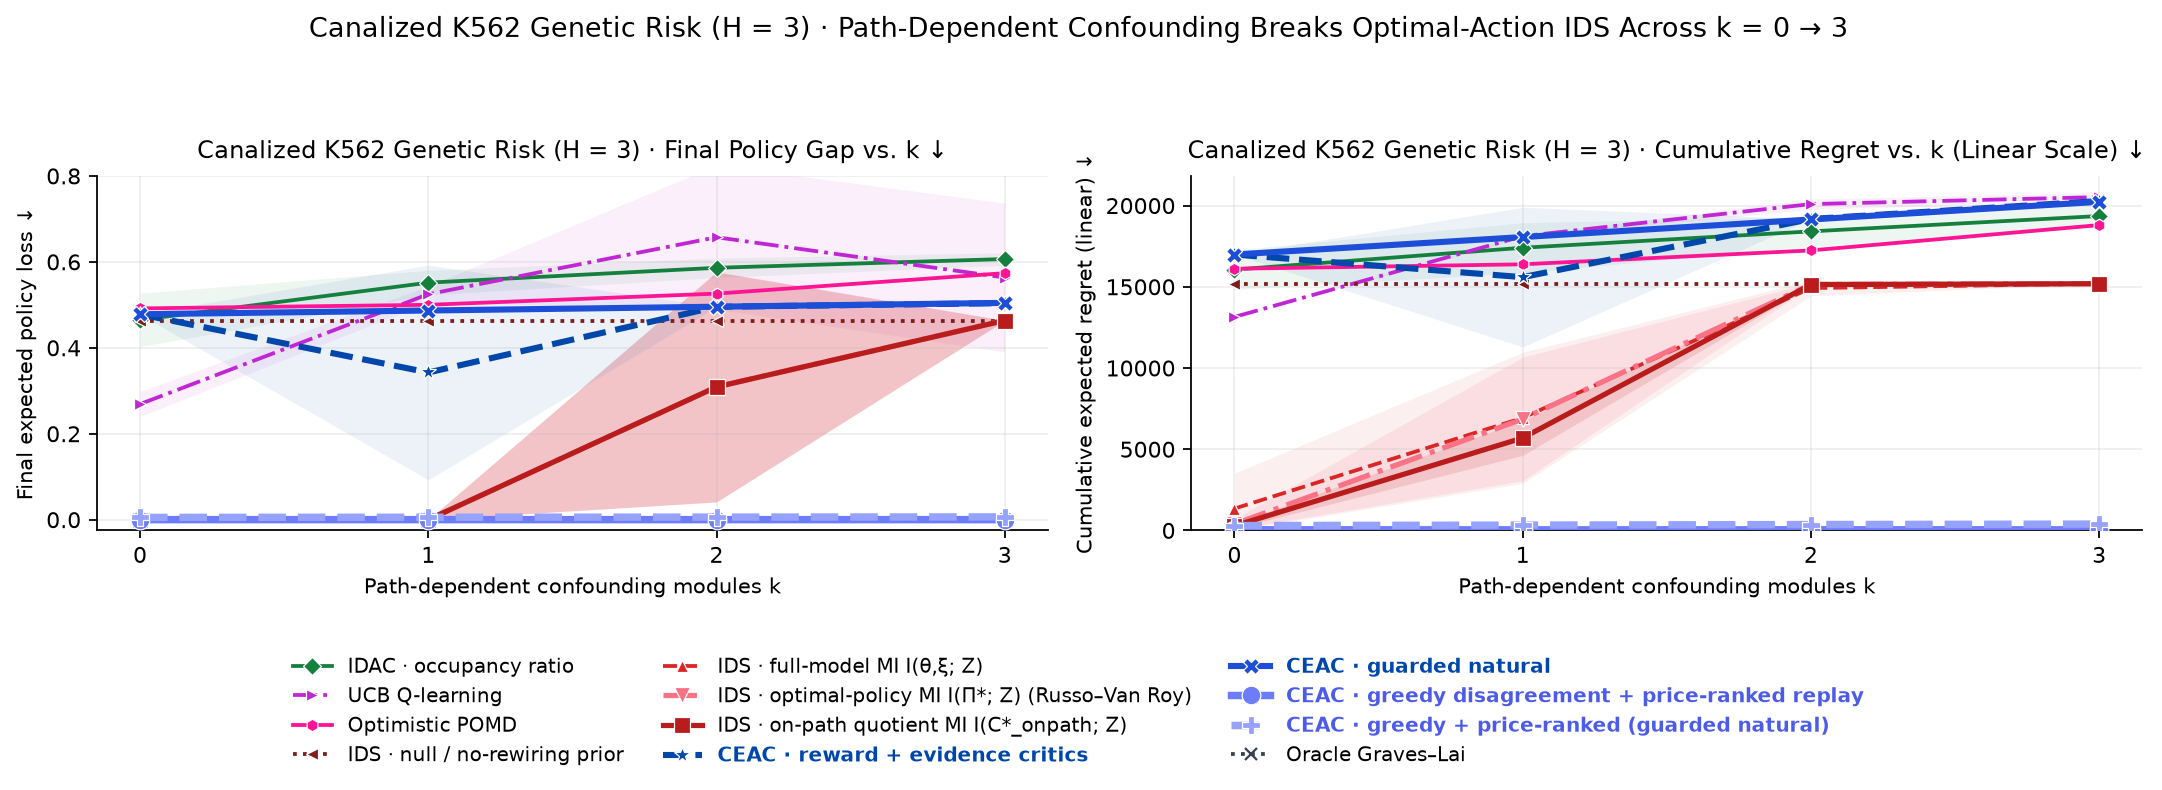

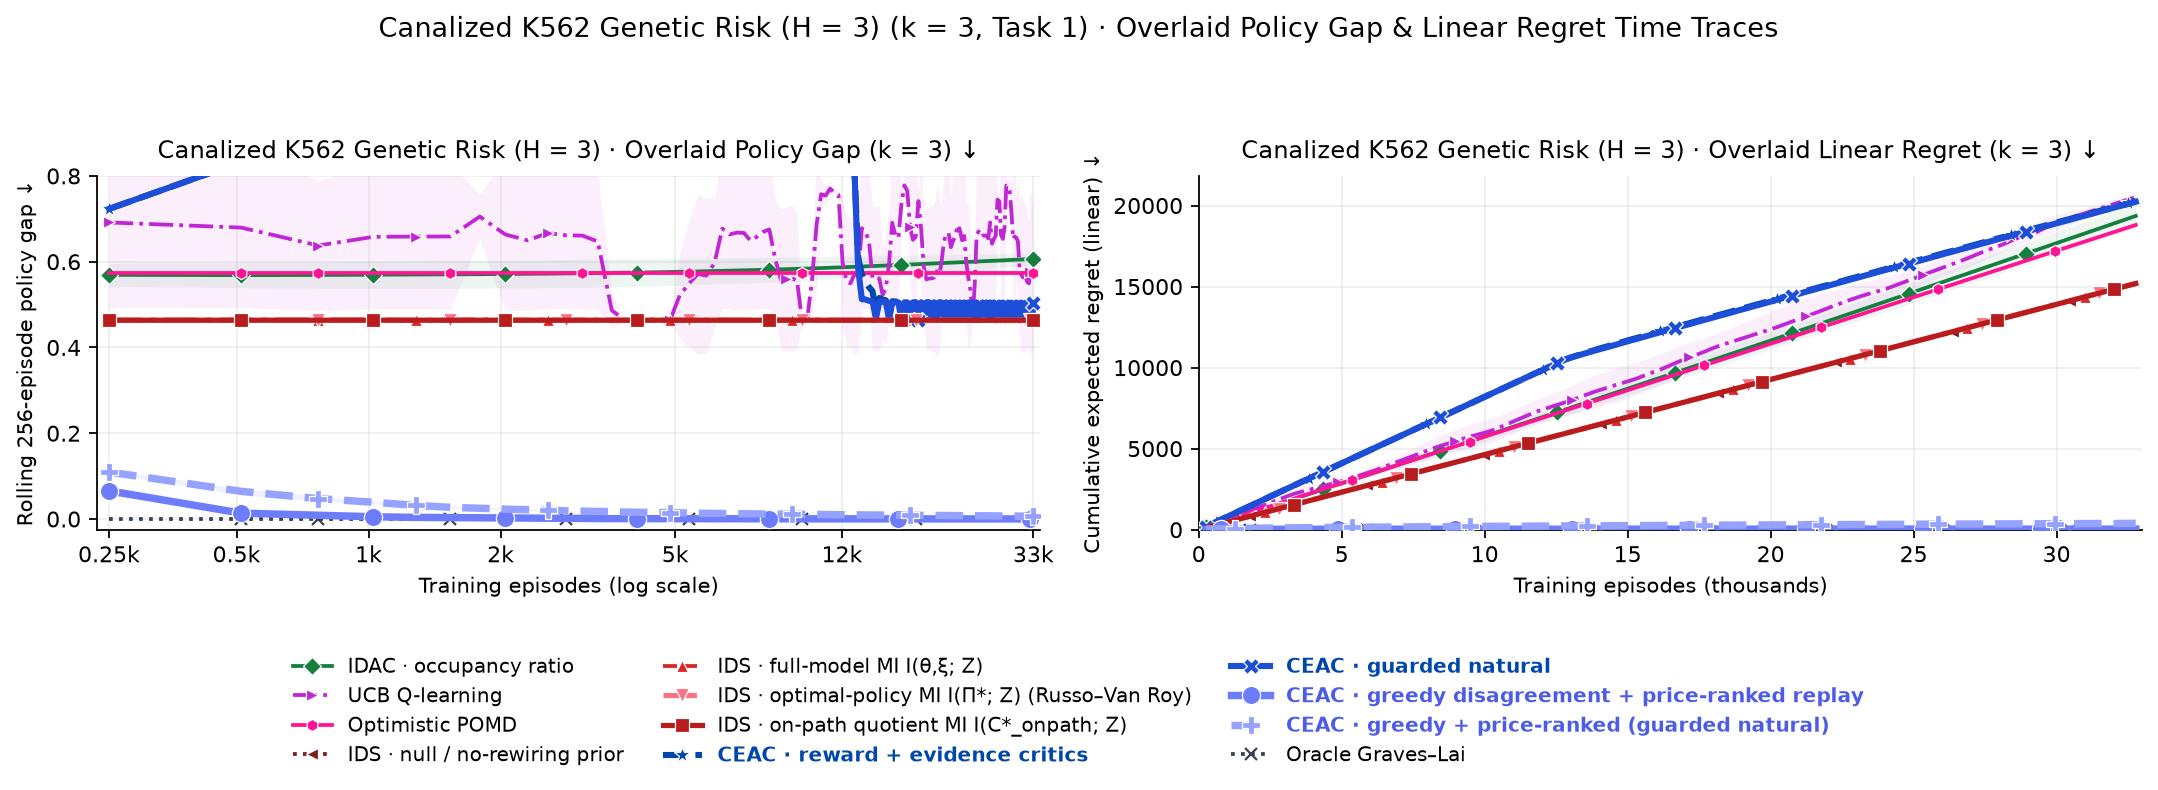

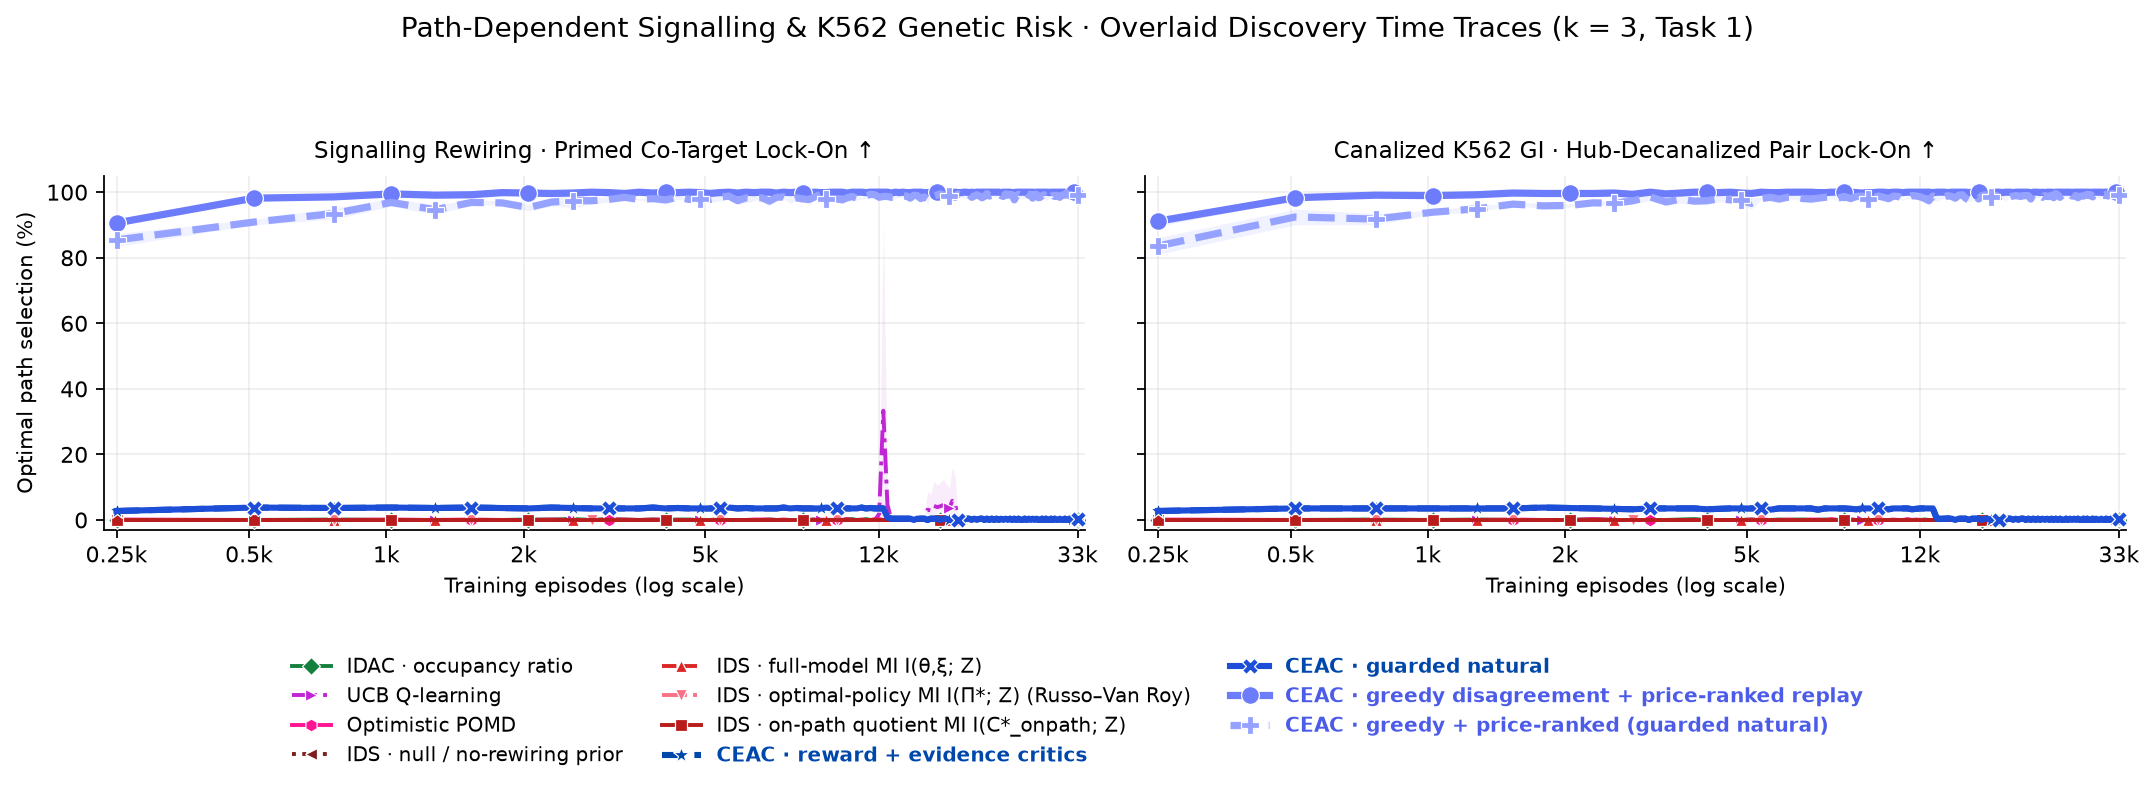

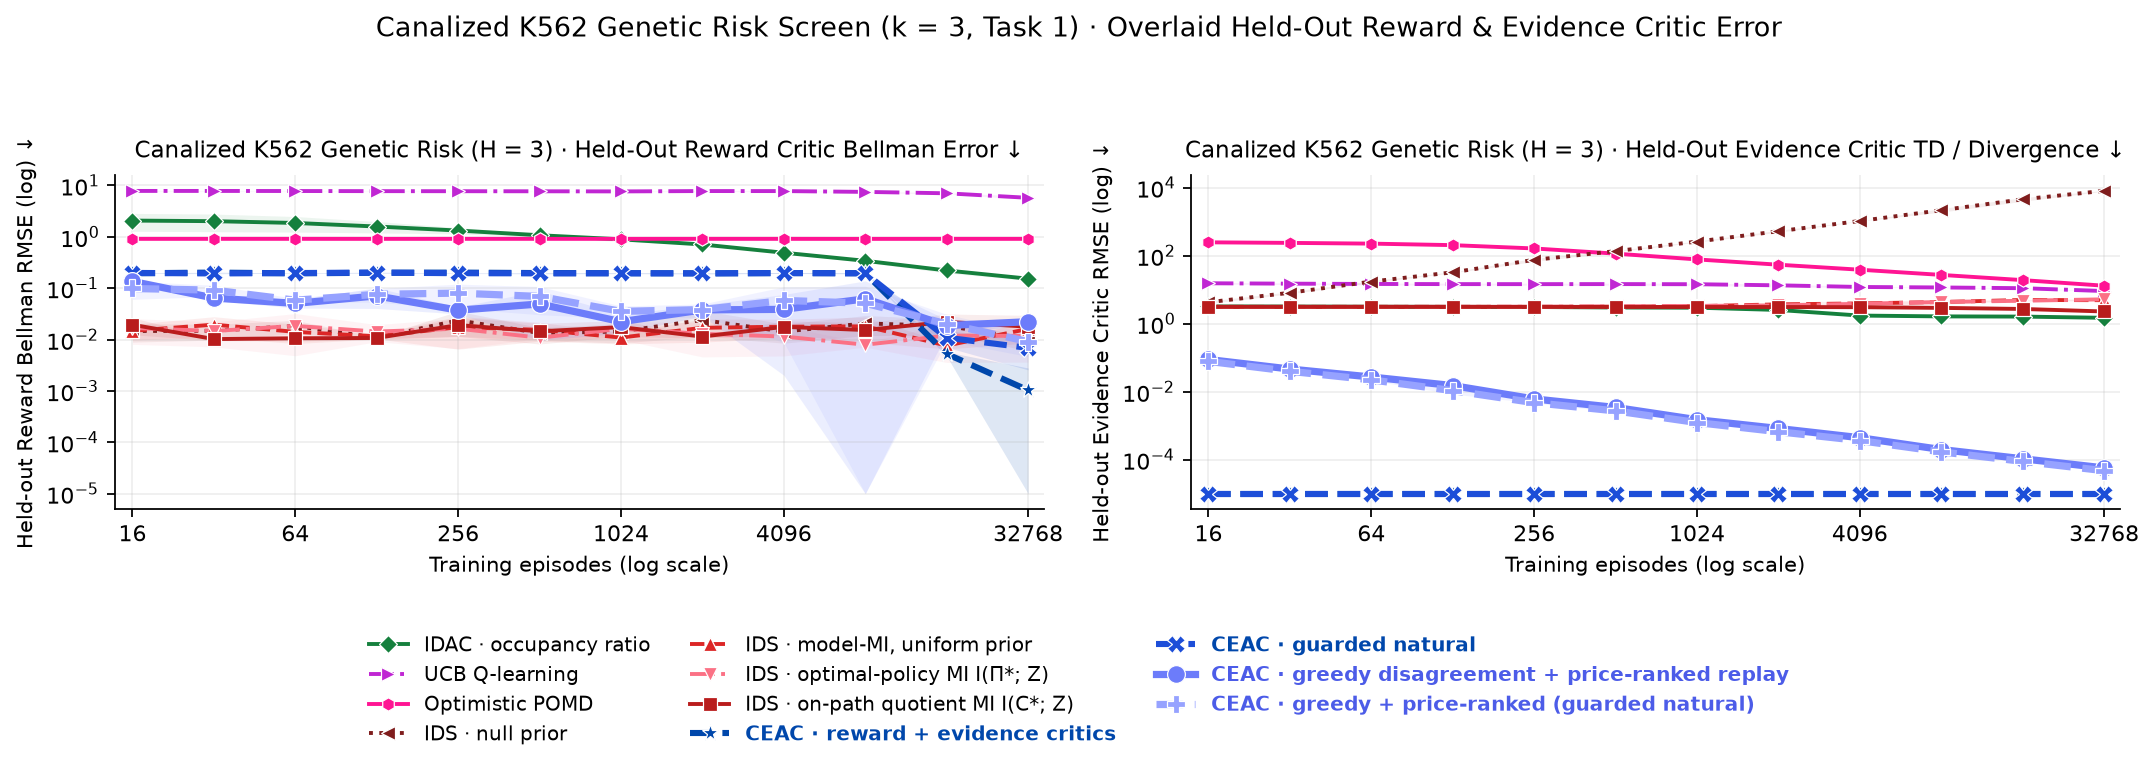

In [6]:
fig = draw_single_pathdep_scaling(pathdep["summary_rows"], "canalized_gi")
plt.show()
fig = draw_single_pathdep_traces(pathdep, "canalized_gi", dose=3)
plt.show()
fig = draw_pathdep_discovery_traces(pathdep, dose=3)
plt.show()
fig = draw_suite_critic_traces(
    critic_audit["cells"],
    [("canalized_gi", "Canalized K562 Genetic Risk (H = 3)")],
    target_dose=3,
    suptitle="Canalized K562 Genetic Risk Screen (k = 3, Task 1) · Overlaid Held-Out Reward & Evidence Critic Error",
    method_order=list(PATHDEP_AUDIT_METHODS),
    ranked_ceac_present=True,
)
plt.show()


---
## Part IV — Consolidated Summary Tables & Reproducible CLI Entrypoints


In [7]:
pd_map = {(r["kind"], r["method"], r["dose"]): r for r in pathdep["summary_rows"] if r["task"] == 1}
print("=== Multi-Step Path-Dependent Signalling & K562 Genetic Risk (Task 1, k = 0 -> k = 3) ===")
print(f"{'Benchmark':36s} | {'Method':48s} | {'k=0 Reg':>8s} | {'k=3 Reg':>8s} | {'k=3 Gap':>7s}")
print("-" * 118)
for kind in ("signalling_rewiring", "canalized_gi"):
    for m in ("idac", "pomd", "ucb_q", "ids_null", "ids_product", "ids_action_tree", "ids_action_onpath", "ceac", "ceac_natural", "ceac_ranked", "ceac_ranked_natural", "oracle"):
        r0, r3 = pd_map[(kind, m, 0)], pd_map[(kind, m, 3)]
        print(
            f"{PATHDEP_KINDS[kind][:36]:36s} | {PATHDEP_LABELS[m][:48]:48s} | {r0['regret_mean']:8,.1f} | "
            f"{r3['regret_mean']:8,.1f} | {r3['late_gap_mean']:7.4f}"
        )

RUNNER_COMMANDS = {
    "unit_tests": ".venv/bin/python -m unittest discover -s tests/pathologies -v",
    "pathdep_signalling_and_gi_study": ".venv/bin/python -m ceac_pathdep.study --tag 20261124_pathdep_v3 --workers 4 --episodes 32768",
    "pathdep_critic_bellman_audit": ".venv/bin/python -m ceac_pathdep.critic_audit --workers 4 --episodes 32768",
    "rebuild_this_notebook": ".venv/bin/python scripts/render_pathologies_notebook.py --execute",
}
print("\n=== Reproducible CLI Entrypoints ===")
for name, cmd in RUNNER_COMMANDS.items():
    print(f"[{name}]  {cmd}")


=== Multi-Step Path-Dependent Signalling & K562 Genetic Risk (Task 1, k = 0 -> k = 3) ===
Benchmark                            | Method                                           |  k=0 Reg |  k=3 Reg | k=3 Gap
----------------------------------------------------------------------------------------------------------------------
Path-Dependent Signalling Rewiring ( | IDAC · occupancy ratio                           | 17,496.6 | 19,114.0 |  0.5885
Path-Dependent Signalling Rewiring ( | Optimistic POMD                                  | 19,308.1 | 19,260.1 |  0.5878
Path-Dependent Signalling Rewiring ( | UCB Q-learning                                   |  9,863.7 | 20,389.4 |  0.6150
Path-Dependent Signalling Rewiring ( | IDS · null / no-rewiring prior                   | 13,762.6 | 13,762.6 |  0.4200
Path-Dependent Signalling Rewiring ( | IDS · full-model MI I(θ,ξ; Z)                    |    232.1 | 13,765.3 |  0.4203
Path-Dependent Signalling Rewiring ( | IDS · optimal-policy MI I(Π*; Z)